<a href="https://colab.research.google.com/github/mugalan/vibration-analysis/blob/main/answers-to-selected-assignments/ME421_Worked_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME421 — Open-ended vibration modelling laboratory
## Fully worked illustrative solution (Weeks 1–4)
This is one possible solution to the companion laboratory notebook. All dimensions, tension, masses, dashpot settings, absorber constraints and recordings used in the numerical example are **synthetic**, not specifications or measurements of the TM1016V. The apparatus datasheet confirms the displacement sensor, exciter encoder, accelerometer, variable-area dashpot and undamped vibration absorber, but does not establish the numerical values or all mounting options used here. Check the supplied user guide and physical apparatus before implementation. In particular, axial tension is an assumption of the laboratory problem, not a stated feature of the datasheet.

Run the notebook from top to bottom. It generates example CSV files and then imports them as if they were experimental recordings. Replace these files with appropriately formatted measured data for a real investigation. The example uses SI units throughout; plots show millimetres and Hz where convenient.

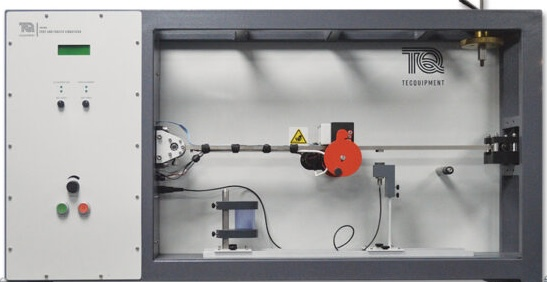

## Resources

- [TecQuipment vibration analyser — video](https://youtu.be/r_ouYEYhR5U)
- [Vibration analysis — Python resources](https://github.com/mugalan/vibration-analysis)
- TecQuipment TM1016V Free and Forced Vibrations datasheet and the user guide available in the laboratory.

The apparatus provides non-contact displacement measurements, acceleration measurements at the exciter, rotational speed and exciter angular position. The VDAS system can also derive velocity and acceleration from displacement measurements. Available components include an adjustable viscous dashpot, additional masses and an undamped vibration absorber. Establish the permissible configurations and adjustment ranges of the actual apparatus before designing experiments.

# Part I — Modelling, identification and validation (end of Week 2)

## Week 1 — Activity 1: Mathematical formulation

### Governing equation

### Governing equation

The transverse displacement $y(x,t)$ of the pinned–pinned beam subjected to a constant axial tension $T$ is modelled by

$$
\rho A\frac{\partial^2 y}{\partial t^2}
+\mathscr{C}_s\frac{\partial y}{\partial t}
+EI\frac{\partial^4 y}{\partial x^4}
-T\frac{\partial^2 y}{\partial x^2}
=f(x,t),
$$

where $\mathscr{C}_s$ is a linear spatial operator representing the equivalent inherent damping of the system.

Assume small transverse displacements, uniform cross-section, constant positive axial tension, ideal pins and linear elasticity. The displacement is measured with respect to the static equilibrium configuration, and hence gravity does not explicitly appear in the incremental equations.

The boundary conditions are

$$
y(0,t)=y(L,t)=0,
\qquad
y_{xx}(0,t)=y_{xx}(L,t)=0.
$$

Let the exciter have a total translating mass $m_e$ located at $x_f$, and let $u=m_r e$ denote the product of the rotating eccentric mass and its eccentricity.

At a constant rotational speed $\omega$, the transverse excitation force is

$$
F(t)=u\omega^2\cos(\omega t),
$$

with the zero of the encoder angle chosen accordingly.

Let $m_i$ denote the concentrated masses attached to the beam at locations $x_i$, including the translating mass of the exciter.

A grounded viscous dashpot attached to the beam at $x_d$ exerts a force

$$
f_d(t)=-c_d\frac{\partial y}{\partial t}(x_d,t).
$$

The resultant governing equation is

$$
\begin{aligned}
\rho A\frac{\partial^2 y}{\partial t^2}
+\mathscr{C}_s\frac{\partial y}{\partial t}
+EI\frac{\partial^4 y}{\partial x^4}
-T\frac{\partial^2 y}{\partial x^2}
={}&
-\sum_i m_i\delta(x-x_i)
\frac{\partial^2 y}{\partial t^2}(x_i,t)\\
&-c_d\delta(x-x_d)
\frac{\partial y}{\partial t}(x_d,t)\\
&+u\omega^2\cos(\omega t)\delta(x-x_f),
\end{aligned}
$$

where $\delta(x)$ denotes the Dirac delta distribution.

Assume that the inherent damping of the beam with its attached masses is classical. That is, in the absence of the external dashpot, the inherent damping preserves the decoupling of the equations governing the natural modes of the system.

Rather than prescribing an explicit differential form for $\mathscr{C}_s$, we characterize its action through the natural modes of the mass-loaded beam. The corresponding modal damping ratios are to be identified experimentally.

Any additional inertia or stiffness introduced by the attachment of the dashpot is initially assumed to be negligible. The validity of this assumption should be assessed experimentally.

### Spatial operator of the unperturbed beam

Consider first the unperturbed beam, by which we mean the beam subjected to axial tension in the absence of concentrated masses, damping and external excitation.

Define the spatial operator $\mathscr{L}$ by

$$
\mathscr{L}\psi
=
\frac{EI}{\rho A}\frac{d^4\psi}{dx^4}
-\frac{T}{\rho A}\frac{d^2\psi}{dx^2}.
$$

Dividing the governing equation of the unperturbed beam by $\rho A$, we obtain

$$
\frac{\partial^2 y}{\partial t^2}
+\mathscr{L}y=0.
$$

Consider the space $\mathscr{H}=L^2(0,L)$ of square-integrable real-valued functions defined on $(0,L)$, equipped with the inner product

$$
\boxed{
\langle\langle\phi,\psi\rangle\rangle
=
\frac{2}{L}\int_0^L\phi(x)\psi(x)\,dx.
}
$$

The domain of the spatial operator is taken to be

$$
\begin{aligned}
\mathscr{D}(\mathscr{L})
=
\big\{
\psi\in H^4(0,L):\;&
\psi(0)=\psi(L)=0,\\
&
\psi''(0)=\psi''(L)=0
\big\},
\end{aligned}
$$

where $H^4(0,L)$ is the space of square-integrable functions whose weak derivatives up to order four are square-integrable.

Thus, the elements of $\mathscr{D}(\mathscr{L})$ satisfy the boundary conditions of the pinned–pinned beam.

### Self-adjointness and positive definiteness

For any $\phi,\psi\in\mathscr{D}(\mathscr{L})$,

$$
\begin{aligned}
\langle\langle\phi,\mathscr{L}\psi\rangle\rangle
={}&
\frac{2EI}{\rho AL}
\int_0^L\phi(x)\psi''''(x)\,dx\\
&-
\frac{2T}{\rho AL}
\int_0^L\phi(x)\psi''(x)\,dx.
\end{aligned}
$$

Integrating by parts and using the boundary conditions, we obtain

$$
\begin{aligned}
\langle\langle\phi,\mathscr{L}\psi\rangle\rangle
={}&
\frac{2EI}{\rho AL}
\int_0^L\phi''(x)\psi''(x)\,dx\\
&+
\frac{2T}{\rho AL}
\int_0^L\phi'(x)\psi'(x)\,dx.
\end{aligned}
$$

Interchanging $\phi$ and $\psi$ gives

$$
\langle\langle\phi,\mathscr{L}\psi\rangle\rangle
=
\langle\langle\mathscr{L}\phi,\psi\rangle\rangle.
$$

Thus, $\mathscr{L}$ is symmetric. With the specified domain, it is also a self-adjoint operator on $\mathscr{H}$.

Furthermore,

$$
\begin{aligned}
\langle\langle\psi,\mathscr{L}\psi\rangle\rangle
={}&
\frac{2EI}{\rho AL}
\int_0^L\left(\psi''(x)\right)^2\,dx\\
&+
\frac{2T}{\rho AL}
\int_0^L\left(\psi'(x)\right)^2\,dx.
\end{aligned}
$$

Since $EI>0$ and $T>0$, and since a nonzero constant function cannot satisfy the boundary conditions,

$$
\langle\langle\psi,\mathscr{L}\psi\rangle\rangle>0
$$

for every nonzero $\psi\in\mathscr{D}(\mathscr{L})$.

Hence, $\mathscr{L}$ is positive definite.

### Eigenfunctions of the spatial operator

Consider the eigenvalue problem

$$
\mathscr{L}\psi_k=\omega_{0k}^2\psi_k.
$$

The eigenfunctions satisfying the boundary conditions are proportional to

$$
\sin\left(\frac{k\pi x}{L}\right),
\qquad k=1,2,\ldots.
$$

The corresponding eigenvalues are

$$
\boxed{
\omega_{0k}^2=
\frac{EI}{\rho A}
\left(\frac{k\pi}{L}\right)^4
+
\frac{T}{\rho A}
\left(\frac{k\pi}{L}\right)^2.
}
$$

Here $\omega_{0k}$ denotes the $k$th natural frequency of the unperturbed beam.

Since $\mathscr{L}$ is self-adjoint,

$$
\begin{aligned}
\omega_{0j}^2
\langle\langle\psi_k,\psi_j\rangle\rangle
&=
\langle\langle\psi_k,\mathscr{L}\psi_j\rangle\rangle\\
&=
\langle\langle\mathscr{L}\psi_k,\psi_j\rangle\rangle\\
&=
\omega_{0k}^2
\langle\langle\psi_k,\psi_j\rangle\rangle.
\end{aligned}
$$

Therefore,

$$
(\omega_{0j}^2-\omega_{0k}^2)
\langle\langle\psi_k,\psi_j\rangle\rangle=0.
$$

Since the eigenvalues are distinct, the corresponding eigenfunctions are orthogonal.

Furthermore,

$$
\frac{2}{L}
\int_0^L
\sin^2\left(\frac{k\pi x}{L}\right)\,dx
=1.
$$

Consequently, choosing

$$
\boxed{
\psi_k(x)=\sin\left(\frac{k\pi x}{L}\right),
}
$$

we obtain

$$
\boxed{
\langle\langle\psi_k,\psi_j\rangle\rangle
=\delta_{kj},
}
$$

where $\delta_{kj}$ denotes the Kronecker delta.

The set $\{\psi_k\}_{k=1}^{\infty}$ forms a complete orthonormal basis for $\mathscr{H}$.

### Representation of the displacement

Using the orthonormal basis $\{\psi_k\}_{k=1}^{\infty}$, express the transverse displacement of the beam as

$$
\boxed{
y(x,t)=\sum_{k=1}^{\infty}z_k(t)\psi_k(x),
}
$$

where

$$
z_k(t)
=
\langle\langle\psi_k,y(\cdot,t)\rangle\rangle
=
\frac{2}{L}\int_0^L\psi_k(x)y(x,t)\,dx.
$$

Since the basis functions are dimensionless, the coefficients $z_k(t)$ have units of displacement.

Every finite truncation of the expansion satisfies the boundary conditions of the beam.

We have

$$
\frac{\partial y}{\partial t}
=
\sum_{j=1}^{\infty}\dot z_j(t)\psi_j(x),
$$

$$
\frac{\partial^2 y}{\partial t^2}
=
\sum_{j=1}^{\infty}\ddot z_j(t)\psi_j(x),
$$

and

$$
\mathscr{L}y
=
\sum_{j=1}^{\infty}
\omega_{0j}^2z_j(t)\psi_j(x).
$$

These expressions are interpreted in the appropriate weak or distributional sense when concentrated forces are present.

### Equations governing the coefficients

Dividing the governing equation by $\rho A$, we obtain

$$
\begin{aligned}
\frac{\partial^2 y}{\partial t^2}
+\frac{1}{\rho A}\mathscr{C}_s
\frac{\partial y}{\partial t}
+\mathscr{L}y
={}&
-\sum_i\frac{m_i}{\rho A}
\delta(x-x_i)
\frac{\partial^2 y}{\partial t^2}(x_i,t)\\
&-\frac{c_d}{\rho A}
\delta(x-x_d)
\frac{\partial y}{\partial t}(x_d,t)\\
&+\frac{u\omega^2}{\rho A}
\cos(\omega t)\delta(x-x_f).
\end{aligned}
$$

Substituting the expansion for $y(x,t)$ and using the linearity of $\mathscr{C}_s$, we obtain

$$
\begin{aligned}
\sum_{j=1}^{\infty}
\left(\ddot z_j+\omega_{0j}^2z_j\right)\psi_j(x)
&+
\frac{1}{\rho A}
\sum_{j=1}^{\infty}
\dot z_j\mathscr{C}_s\psi_j(x)\\
={}&
-\sum_i\frac{m_i}{\rho A}
\delta(x-x_i)
\sum_{j=1}^{\infty}\ddot z_j\psi_j(x_i)\\
&-\frac{c_d}{\rho A}
\delta(x-x_d)
\sum_{j=1}^{\infty}\dot z_j\psi_j(x_d)\\
&+\frac{u\omega^2}{\rho A}
\cos(\omega t)\delta(x-x_f).
\end{aligned}
$$

Taking the inner product with $\psi_k$, using orthonormality and the distributional identity

$$
\frac{2}{L}\int_0^L
\psi_k(x)\delta(x-a)\,dx
=
\frac{2}{L}\psi_k(a),
$$

we obtain

$$
\begin{aligned}
\ddot z_k+\omega_{0k}^2z_k
&+
\frac{1}{\rho A}
\sum_{j=1}^{\infty}
\langle\langle
\psi_k,\mathscr{C}_s\psi_j
\rangle\rangle\dot z_j\\
={}&
-\sum_i\frac{2m_i}{\rho AL}\psi_k(x_i)
\sum_{j=1}^{\infty}\psi_j(x_i)\ddot z_j\\
&-\frac{2c_d}{\rho AL}\psi_k(x_d)
\sum_{j=1}^{\infty}\psi_j(x_d)\dot z_j\\
&+\frac{2u\omega^2}{\rho AL}
\psi_k(x_f)\cos(\omega t).
\end{aligned}
$$

Let

$$
m_b=\rho AL
$$

denote the total mass of the beam, and define

$$
a_{kj}=
\frac{1}{\rho A}
\langle\langle
\psi_k,\mathscr{C}_s\psi_j
\rangle\rangle.
$$

If the damping operator includes localized contributions, the above inner product is interpreted as the corresponding distributional pairing.

The equations governing the coefficients can therefore be expressed as

$$
\boxed{
\begin{aligned}
\ddot z_k
+\sum_{j=1}^{\infty}a_{kj}\dot z_j
+\omega_{0k}^2z_k
={}&
-\sum_i\frac{2m_i}{m_b}\psi_k(x_i)
\sum_{j=1}^{\infty}\psi_j(x_i)\ddot z_j\\
&-\frac{2c_d}{m_b}\psi_k(x_d)
\sum_{j=1}^{\infty}\psi_j(x_d)\dot z_j\\
&+\frac{2u\omega^2}{m_b}
\psi_k(x_f)\cos(\omega t).
\end{aligned}
}
$$

Observe that, in the absence of concentrated masses, inherent damping, the external dashpot and external excitation, the equations reduce to

$$
\boxed{
\ddot z_k+\omega_{0k}^2z_k=0.
}
$$

Thus, the equations governing the coefficients $z_k$ are decoupled for the unperturbed beam.

The concentrated masses introduce inertial coupling, while the inherent damping and the localized dashpot may introduce damping coupling between the equations governing the coefficients $z_k$.

### Finite-dimensional approximation

Retaining the first $n$ basis functions, we approximate the displacement by

$$
y(x,t)\approx
\sum_{k=1}^{n}z_k(t)\psi_k(x).
$$

Define

$$
z=
\begin{bmatrix}
z_1&z_2&\cdots&z_n
\end{bmatrix}^{T}
$$

and

$$
\Psi(x)=
\begin{bmatrix}
\psi_1(x)\\
\psi_2(x)\\
\vdots\\
\psi_n(x)
\end{bmatrix}.
$$

Then

$$
y(x,t)\approx\Psi^T(x)z(t).
$$

Define the dimensionless symmetric positive definite matrix

$$
\boxed{
M=I_n+
\sum_i\frac{2m_i}{m_b}
\Psi(x_i)\Psi^T(x_i),
}
$$

which accounts for the inertial contributions of the concentrated masses attached to the beam.

Collecting the terms involving $\ddot z_k$ and using the invertibility of $M$, the equations governing the coefficients can be expressed in the normalized matrix form

$$
\boxed{
\ddot z+(C_s+C_d)\dot z+\Omega z=\gamma(t),
}
$$

where

$$
\boxed{
\Omega=
M^{-1}\operatorname{diag}
(\omega_{01}^2,\omega_{02}^2,\ldots,\omega_{0n}^2),
}
$$

$$
\boxed{
C_s=
M^{-1}
\left[a_{kj}\right]_{k,j=1}^{n},
}
$$

$$
\boxed{
C_d=
\frac{2c_d}{m_b}
M^{-1}\Psi(x_d)\Psi^T(x_d),
}
$$

and

$$
\boxed{
\gamma(t)=
\frac{2u\omega^2}{m_b}
M^{-1}\Psi(x_f)\cos(\omega t).
}
$$

The matrix $\Omega$ accounts for both the elastic and geometric stiffness of the beam and the inertial contributions of the attached masses, while $C_s$ and $C_d$ account for the inherent damping and the damping introduced by the external viscous dashpot, respectively.

For convenience, defining

$$
b=\Psi(x_d),
$$

the complete normalized mathematical model can also be expressed as

$$
\boxed{
\ddot z+
\left(C_s+\frac{2c_d}{m_b}M^{-1}bb^T\right)\dot z
+\Omega z
=\gamma(t).
}
$$

The matrix $\Omega$ has units of $\mathrm{s}^{-2}$, the matrices $C_s$ and $C_d$ have units of $\mathrm{s}^{-1}$, and $\gamma(t)$ has units of acceleration.

Although $\Omega$ is not necessarily symmetric with respect to the standard Euclidean inner product, it is self-adjoint with respect to the inner product

$$
\langle\langle v,w\rangle\rangle_M=v^TMw.
$$

Indeed,

$$
M\Omega
=
\operatorname{diag}
(\omega_{01}^2,\omega_{02}^2,\ldots,\omega_{0n}^2)
=
\Omega^TM.
$$

Furthermore, for any nonzero $v\in\mathbb{R}^n$,

$$
\langle\langle v,\Omega v\rangle\rangle_M
=
v^TM\Omega v
=
\sum_{k=1}^{n}\omega_{0k}^2v_k^2
>0.
$$

Consequently, $\Omega$ admits a complete basis of eigenvectors that are orthonormal with respect to this inner product, and its eigenvalues are real and positive.

The number of retained basis functions should be determined based on the required accuracy of the mathematical model over the frequency range of interest.

### Classical inherent damping

Assume that the inherent damping of the mass-loaded beam is classical. In the finite-dimensional approximation, this implies that $C_s$ and $\Omega$ admit a common basis of eigenvectors.

Let $\bar z_k$ and $\omega_k^2$ denote the eigenvectors and corresponding eigenvalues of $\Omega$, respectively, such that

$$
\boxed{
\Omega\bar z_k=\omega_k^2\bar z_k.
}
$$

Here $\omega_k$ denotes the $k$th undamped natural frequency of the mass-loaded beam.

Under the assumption of classical inherent damping, we have

$$
\boxed{
C_s\bar z_k=2\zeta_k\omega_k\bar z_k,
}
$$

where $\zeta_k$ denotes the inherent damping ratio associated with the $k$th natural mode of the mass-loaded beam.

Choose the eigenvectors of $\Omega$ to be orthonormal with respect to the $M$-weighted inner product. That is,

$$
\langle\langle
\bar z_k,\bar z_j
\rangle\rangle_M
=
\bar z_k^TM\bar z_j
=
\delta_{kj}.
$$

Define

$$
V=
\begin{bmatrix}
\bar z_1&\bar z_2&\cdots&\bar z_n
\end{bmatrix}.
$$

It follows that

$$
V^TMV=I_n,
$$

and hence

$$
V^{-1}=V^TM,
\qquad
V^{-1}M^{-1}=V^T.
$$

Furthermore,

$$
V^{-1}\Omega V
=
\Lambda
=
\operatorname{diag}
(\omega_1^2,\ldots,\omega_n^2),
$$

and

$$
V^{-1}C_sV
=
D_s
=
\operatorname{diag}
(2\zeta_1\omega_1,\ldots,2\zeta_n\omega_n).
$$

Consequently,

$$
\boxed{
C_s=VD_sV^{-1}.
}
$$

Thus, rather than explicitly determining the spatial damping operator $\mathscr{C}_s$, its contribution to the finite-dimensional mathematical model can be characterized entirely through the inherent modal damping ratios $\zeta_k$.

The assumption of classical inherent damping therefore provides a convenient parameterization of the unknown damping matrix $C_s$.

### Modal decomposition

Introducing the modal coordinates $q$ through

$$
z=Vq,
$$

and premultiplying the normalized governing equations by $V^{-1}$, we obtain

$$
\ddot q+
V^{-1}(C_s+C_d)V\dot q
+
V^{-1}\Omega Vq
=
V^{-1}\gamma(t).
$$

Using the expressions obtained above,

$$
\ddot q+
\left(
D_s+
\frac{2c_d}{m_b}
V^{-1}M^{-1}bb^TV
\right)\dot q
+\Lambda q
=
V^{-1}\gamma(t).
$$

Since

$$
V^{-1}M^{-1}=V^T,
$$

we obtain

$$
\ddot q+
\left(
D_s+
\frac{2c_d}{m_b}V^Tbb^TV
\right)\dot q
+\Lambda q
=
\frac{2u\omega^2}{m_b}
V^T\Psi(x_f)\cos(\omega t).
$$

Defining

$$
g=V^Tb,
\qquad
p=V^T\Psi(x_f),
$$

the modal equations become

$$
\boxed{
\ddot q+
\left(
D_s+\frac{2c_d}{m_b}gg^T
\right)\dot q
+\Lambda q
=
\frac{2u\omega^2}{m_b}p\cos(\omega t).
}
$$

The corresponding spatial mode shapes of the mass-loaded beam are

$$
\boxed{
\chi_k(x)=\Psi^T(x)\bar z_k.
}
$$

Hence,

$$
\begin{aligned}
y(x,t)
&\approx\Psi^T(x)z(t)\\
&=\Psi^T(x)Vq(t)\\
&=\sum_{k=1}^{n}q_k(t)\chi_k(x).
\end{aligned}
$$

Therefore,

$$
\boxed{
y(x,t)\approx
\sum_{k=1}^{n}q_k(t)\chi_k(x).
}
$$

Note that the spatial mode shapes $\chi_k(x)$ of the mass-loaded beam are, in general, different from the orthonormal spatial basis functions $\psi_k(x)$ of the unperturbed beam.

Since

$$
g_k=\chi_k(x_d),
\qquad
p_k=\chi_k(x_f),
$$

the equations governing the modal coordinates can be expressed as

$$
\boxed{
\begin{aligned}
\ddot q_k
+2\zeta_k\omega_k\dot q_k
+\omega_k^2q_k
={}&
-\frac{2c_d}{m_b}
\chi_k(x_d)
\sum_{j=1}^{n}\chi_j(x_d)\dot q_j\\
&+
\frac{2u\omega^2}{m_b}
\chi_k(x_f)\cos(\omega t).
\end{aligned}
}
$$

In the absence of the external dashpot, the modal equations are decoupled and reduce to

$$
\boxed{
\ddot q_k+
2\zeta_k\omega_k\dot q_k+
\omega_k^2q_k
=
\frac{2u\omega^2}{m_b}
\chi_k(x_f)\cos(\omega t).
}
$$

Thus, classical inherent damping preserves the decoupling of the modal equations, whereas the external viscous dashpot generally introduces coupling between them.

The unknown inherent modal damping ratios $\zeta_k$ and the physical dashpot damping coefficient $c_d$ are to be identified experimentally.

### Representation of the measured quantities

Recall that the transverse displacement of the beam is approximately represented by

$$
y(x,t)\approx
\sum_{k=1}^{n}q_k(t)\chi_k(x),
$$

where $\chi_k(x)$ are the natural mode shapes of the mass-loaded beam.

For convenience, define

$$
g_k=\chi_k(x_d),
\qquad
p_k=\chi_k(x_f),
\qquad
h_k=\chi_k(x_m),
$$

where $x_d$, $x_f$ and $x_m$ denote the locations of the dashpot, exciter and displacement sensor, respectively.

The displacement measured by the non-contact displacement sensor is approximately given by

$$
y(x_m,t)\approx
\sum_{k=1}^{n}h_kq_k(t).
$$

Similarly, the velocity and acceleration at the measurement location are approximately given by

$$
\frac{\partial y}{\partial t}(x_m,t)
\approx
\sum_{k=1}^{n}h_k\dot q_k(t),
$$

and

$$
\frac{\partial^2 y}{\partial t^2}(x_m,t)
\approx
\sum_{k=1}^{n}h_k\ddot q_k(t).
$$

The acceleration measured by the accelerometer located at the exciter is approximately given by

$$
\frac{\partial^2 y}{\partial t^2}(x_f,t)
\approx
\sum_{k=1}^{n}p_k\ddot q_k(t).
$$

If the displacement sensor and the exciter are located at the same position, then $h_k=p_k$.

### Model reduction and choice of dominant modes

Recall that the equations governing the modal coordinates are

$$
\begin{aligned}
\ddot q_k
+2\zeta_k\omega_k\dot q_k
+\omega_k^2q_k
={}&
-\frac{2c_d}{m_b}
g_k\sum_{j=1}^{n}g_j\dot q_j\\
&+
\frac{2u\omega^2}{m_b}
p_k\cos(\omega t).
\end{aligned}
$$

In the absence of the external dashpot, the modal equations are decoupled.

The contribution of each mode to the forced vibration response depends on its natural frequency $\omega_k$, inherent damping ratio $\zeta_k$, excitation factor $p_k$ and measurement factor $h_k$.

For the unperturbed pinned–pinned beam,

$$
\psi_k(x)=\sin\left(\frac{k\pi x}{L}\right).
$$

Since the exciter is located at the midpoint of the beam, $x_f=L/2$, we have

$$
\psi_k(x_f)=
\begin{cases}
(-1)^{(k-1)/2}, & k=1,3,5,\ldots,\\
0, & k=2,4,6,\ldots.
\end{cases}
$$

For a symmetric distribution of the attached masses, the natural mode shapes $\chi_k(x)$ of the mass-loaded beam also possess symmetry or antisymmetry about the midpoint.

For the antisymmetric modes,

$$
p_k=\chi_k(L/2)=0.
$$

Consequently, these modes are not directly excited by the transverse force applied at the midpoint of the beam.

Similarly, if the displacement sensor is located at the midpoint, then $h_k=0$ for the antisymmetric modes.

However, the introduction of an off-centre dashpot can indirectly excite these modes through damping-induced modal coupling.

Since our primary interest is the dynamic behaviour of the beam in the vicinity of its first resonance, we retain, as a starting approximation, the first two symmetric natural modes of the mass-loaded beam.

For convenience, these modes are denoted by $k=1,3$. Their actual ordering and symmetry should be established numerically.

### Two-mode approximation

Retaining only these two modes, the transverse displacement of the beam is approximately given by

$$
\boxed{
y(x,t)\approx
q_1(t)\chi_1(x)+q_3(t)\chi_3(x).
}
$$

The corresponding modal equations are

$$
\boxed{
\begin{aligned}
\ddot q_1
+2\zeta_1\omega_1\dot q_1
+\omega_1^2q_1
={}&
-\frac{2c_d}{m_b}
g_1(g_1\dot q_1+g_3\dot q_3)\\
&+\frac{2u\omega^2}{m_b}
p_1\cos(\omega t),
\\[8pt]
\ddot q_3
+2\zeta_3\omega_3\dot q_3
+\omega_3^2q_3
={}&
-\frac{2c_d}{m_b}
g_3(g_1\dot q_1+g_3\dot q_3)\\
&+\frac{2u\omega^2}{m_b}
p_3\cos(\omega t).
\end{aligned}
}
$$

Define

$$
q_r=
\begin{bmatrix}
q_1\\
q_3
\end{bmatrix},
\qquad
g_r=
\begin{bmatrix}
g_1\\
g_3
\end{bmatrix},
\qquad
p_r=
\begin{bmatrix}
p_1\\
p_3
\end{bmatrix},
\qquad
h_r=
\begin{bmatrix}
h_1\\
h_3
\end{bmatrix}.
$$

The resultant two-degree-of-freedom mathematical model can be expressed as

$$
\boxed{
\ddot q_r+D_r\dot q_r+\Lambda_rq_r
=
\frac{2u\omega^2}{m_b}
p_r\cos(\omega t),
}
$$

where

$$
\Lambda_r=
\begin{bmatrix}
\omega_1^2&0\\
0&\omega_3^2
\end{bmatrix},
$$

and

$$
\boxed{
D_r=
\begin{bmatrix}
2\zeta_1\omega_1&0\\
0&2\zeta_3\omega_3
\end{bmatrix}
+
\frac{2c_d}{m_b}
\begin{bmatrix}
g_1^2&g_1g_3\\
g_1g_3&g_3^2
\end{bmatrix}.
}
$$

Observe that the external dashpot introduces coupling between the two retained modal equations whenever $c_dg_1g_3\neq 0$, even though the inherent damping is assumed to be classical.

The corresponding displacement and acceleration measurements are approximately given by

$$
\boxed{
y(x_m,t)\approx h_r^Tq_r(t),
}
$$

and

$$
\boxed{
\frac{\partial^2 y}{\partial t^2}(x_f,t)
\approx p_r^T\ddot q_r(t).
}
$$

The adequacy of the two-mode approximation should be assessed by comparing its predictions with those of higher-order models, including the antisymmetric modes, and with experimental measurements.



### Steady-state forced vibration response

At a constant excitation frequency $\omega$, let the steady-state solution of the two-mode model be represented by

$$
q_r(t)=\operatorname{Re}
\left(\widehat{q}_r(\omega)e^{\mathrm{i}\omega t}\right).
$$

Substituting into the governing equations, we obtain

$$
\left(
-\omega^2 I_2+\mathrm{i}\omega D_r+\Lambda_r
\right)\widehat q_r(\omega)
=
\frac{2u\omega^2}{m_b}p_r.
$$

Consequently,

$$
\boxed{
\widehat q_r(\omega)
=
\frac{2u\omega^2}{m_b}
\left(
\Lambda_r-\omega^2I_2+\mathrm{i}\omega D_r
\right)^{-1}p_r.
}
$$

The complex displacement response at the measurement location is therefore

$$
\boxed{
\widehat y(x_m,\omega)=h_r^T\widehat q_r(\omega).
}
$$

The corresponding steady-state displacement amplitude and phase relative to the excitation force are

$$
Y(x_m,\omega)
=
\left|\widehat y(x_m,\omega)\right|,
$$

and

$$
\varphi(x_m,\omega)
=
\arg\left(\widehat y(x_m,\omega)\right).
$$

Similarly, the complex acceleration response at the exciter location is

$$
\boxed{
\widehat a(x_f,\omega)
=
-\omega^2p_r^T\widehat q_r(\omega).
}
$$

These expressions allow us to directly compare the predicted amplitude and phase responses with experimental measurements.

### Single-mode approximation

In the immediate vicinity of the first resonance, the contribution of the higher modes may be sufficiently small to justify a single-mode approximation.

Retaining only the first mode, we obtain

$$
y(x,t)\approx q_1(t)\chi_1(x).
$$

The corresponding modal equation becomes

$$
\boxed{
\ddot q_1+
\left(
2\zeta_1\omega_1+
\frac{2c_d}{m_b}g_1^2
\right)\dot q_1
+\omega_1^2q_1
=
\frac{2u\omega^2}{m_b}
p_1\cos(\omega t).
}
$$

Defining the effective damping ratio of the single-mode approximation as

$$
\boxed{
\zeta_{1,\mathrm{eff}}
=
\zeta_1+
\frac{c_dg_1^2}{m_b\omega_1},
}
$$

the governing equation can be expressed as

$$
\boxed{
\ddot q_1+
2\zeta_{1,\mathrm{eff}}\omega_1\dot q_1
+\omega_1^2q_1
=
\frac{2u\omega^2}{m_b}
p_1\cos(\omega t).
}
$$

The corresponding complex steady-state displacement response at the measurement location is

$$
\boxed{
\widehat y(x_m,\omega)
=
\frac{2u\omega^2}{m_b}
\frac{h_1p_1}
{\omega_1^2-\omega^2+
2\mathrm{i}\zeta_{1,\mathrm{eff}}\omega_1\omega}.
}
$$

The single-mode approximation provides a particularly simple mathematical model for estimating the damping characteristics of the system and predicting its dynamic behaviour near the first resonance.

The validity of this approximation should be assessed by comparing its predictions with those of the two-mode and higher-order models.

### Experimental identification and validation

The unknown damping parameters of the two-mode model are

$$
\zeta_1,\qquad \zeta_3,\qquad c_d.
$$

Develop and justify an appropriate experimental methodology to independently estimate the inherent modal damping ratios and the physical damping coefficient of the external viscous dashpot.

Since the dashpot is adjustable, investigate the relationship between its physical setting $s$ and its effective damping coefficient,

$$
c_d=c_d(s).
$$

Investigate whether the available experimental measurements contain sufficient information to reliably identify all the unknown damping parameters.

In particular, measurements dominated by the first mode may provide insufficient information to reliably identify $\zeta_3$.

Furthermore, measurements obtained at a single dashpot setting may be insufficient to independently identify the inherent damping and dashpot damping contributions.

Assess the adequacy of the single-mode and two-mode approximations by comparing their predictions with those of higher-order models and with experimental measurements.

The identified mathematical model should subsequently be validated using experimental measurements that were not used for parameter estimation.

The experimentally validated mathematical model will form the basis for the design of a dynamic vibration absorber in Part II of this laboratory.

In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import eigh
from scipy.optimize import least_squares
from scipy.integrate import solve_ivp
from pathlib import Path
from IPython.display import display

rng = np.random.default_rng(421)

DATA = Path('me421_dummy_data')
DATA.mkdir(exist_ok=True)

# Illustrative values only; replace with measured geometry and masses.
L, rho, E, width, thickness, T = .80, 7850., 200e9, .025, .004, 100.

A = width * thickness
I = width * thickness**3 / 12

# Total mass of the beam
mb = rho * A * L

# Exciter, measurement and dashpot locations
xf, xm, xd = L/2, L/2, L*.40

# Exciter mass and rotating unbalance
me, u = 1.2, 2.0e-5  # kg, kg m

attached = [(me, xf)]


def basis(x, n):
    """
    Orthonormal spatial basis functions with respect to
    the normalized spatial inner product.
    """
    return np.sin(np.arange(1, n+1) * np.pi * x / L)


def beam(n):
    """
    Construct the normalized mathematical model of the
    mass-loaded beam and compute its natural modes.
    """

    # Dimensionless mass matrix
    M = np.eye(n)

    for mass, x in attached:
        v = basis(x, n)
        M += (2 * mass / mb) * np.outer(v, v)

    # Natural frequencies squared of the unperturbed beam
    k = np.arange(1, n+1) * np.pi / L

    w0_squared = (
        E * I * k**4 + T * k**2
    ) / (rho * A)

    # Normalized stiffness matrix
    K = np.diag(w0_squared)

    # Inertia-normalized stiffness operator
    Omega = np.linalg.solve(M, K)

    # Solve the equivalent generalized eigenvalue problem
    # K v = w^2 M v
    #
    # eigh automatically ensures V.T @ M @ V = I
    w2, V = eigh(K, M)

    w = np.sqrt(w2)

    return M, Omega, w, V


# Construct the beam model
n = 9

M, Omega, w, V = beam(n)

# Modal excitation factors
p = V.T @ basis(xf, n)

# Modal damping-location factors
g = V.T @ basis(xd, n)

# Modal measurement factors
h = V.T @ basis(xm, n)

print('Beam mass (kg):', mb)

display(pd.DataFrame({
    'mode': np.arange(1, n+1),
    'frequency_Hz': w / (2*np.pi),
    'excitation_coupling': p,
    'dashpot_coupling': g,
    'measurement_coupling': h
}))

# Convergence of the first natural frequency
display(pd.DataFrame(
    [(n, beam(n)[2][0] / (2*np.pi))
     for n in [1, 3, 5, 9, 15]],
    columns=['basis_size', 'first_frequency_Hz']
))

# Verify the eigenvector normalization
print('Mass normalization error:',
      np.linalg.norm(V.T @ M @ V - np.eye(n)))

# Verify the modal decomposition
print('Modal decomposition error:',
      np.linalg.norm(Omega @ V - V @ np.diag(w**2)))

Beam mass (kg): 0.6280000000000001


,mode,frequency_Hz,excitation_coupling,dashpot_coupling,measurement_coupling
0,1,7.223595,4.567070e-01,0.431321,4.567070e-01
1,2,58.933834,-1.168261e-15,0.587785,-1.168261e-15
2,3,96.120873,-1.582436e-01,0.180273,-1.582436e-01
3,4,230.613559,1.005303e-16,0.951057,1.005303e-16
4,5,298.197712,-9.406277e-02,0.674766,-9.406277e-02
5,6,516.718230,3.381712e-17,0.951057,3.381712e-17
6,7,618.170723,6.438824e-02,-0.973402,6.438824e-02
7,8,917.260965,-3.037976e-17,-0.587785,-3.037976e-17
8,9,1062.483065,-4.514213e-02,0.937360,-4.514213e-02


,basis_size,first_frequency_Hz
0,1,7.263681
1,3,7.229637
2,5,7.225184
3,9,7.223595
4,15,7.223250


Mass normalization error: 2.193425722107696e-15
Modal decomposition error: 4.344808694829487e-08


In [ ]:
# Identify modes with non-negligible excitation coupling
tol = 1e-8 * np.max(np.abs(p))

excited_modes = np.flatnonzero(np.abs(p) > tol)

# Retain the first two directly excited modes
idx = excited_modes[:2]

wr = w[idx]
Vr = V[:, idx]

pr = p[idx]
gr = g[idx]
hr = h[idx]

Lambda_r = np.diag(wr**2)

display(pd.DataFrame({
    'retained_mode': idx + 1,
    'frequency_Hz': wr / (2*np.pi),
    'excitation_coupling': pr,
    'dashpot_coupling': gr,
    'measurement_coupling': hr
}))

,retained_mode,frequency_Hz,excitation_coupling,dashpot_coupling,measurement_coupling
0,1,7.223595,0.456707,0.431321,0.456707
1,3,96.120873,-0.158244,0.180273,-0.158244


In [ ]:
def damping_matrix(zeta, cd):
    Ds = np.diag(2 * np.asarray(zeta) * wr)

    Dd = (2 * cd / mb) * np.outer(gr, gr)

    return Ds + Dd

In [ ]:
def excitation(t, omega):
    return (2 * u * omega**2 / mb) * pr * np.cos(omega*t)

,Mode,Natural frequency (rad/s),Natural frequency (Hz),Excitation factor,Dashpot factor,Measurement factor
0,1,45.387185,7.223595,0.456707,0.431321,0.456707
1,3,603.945256,96.120873,-0.158244,0.180273,-0.158244


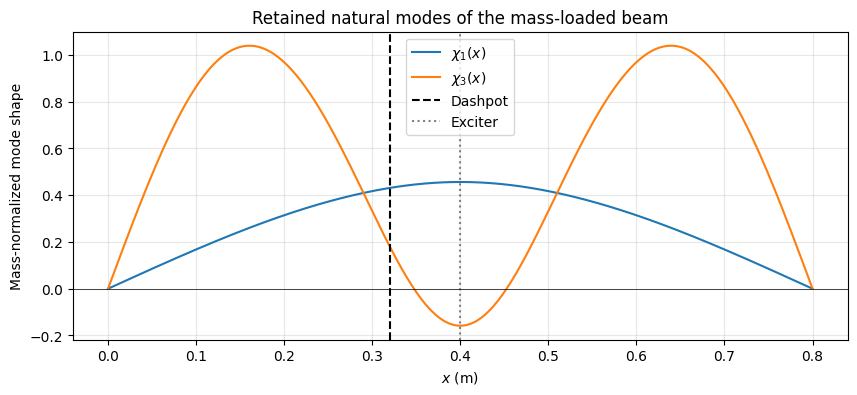

In [6]:
# Retain the first two directly excited modes
tol = 1e-8 * np.max(np.abs(p))
idx = np.flatnonzero(np.abs(p) > tol)[:2]

wr = w[idx]
Vr = V[:, idx]

pr = p[idx]
gr = g[idx]
hr = h[idx]

Lambda_r = np.diag(wr**2)

# Display the retained modal properties
display(pd.DataFrame({
    'Mode': idx + 1,
    'Natural frequency (rad/s)': wr,
    'Natural frequency (Hz)': wr / (2*np.pi),
    'Excitation factor': pr,
    'Dashpot factor': gr,
    'Measurement factor': hr
}))

# Plot the retained spatial mode shapes
x = np.linspace(0, L, 301)

plt.figure(figsize=(10, 4))

for j, k in enumerate(idx):
    chi = np.array([
        basis(xx, n) @ Vr[:, j]
        for xx in x
    ])

    plt.plot(x, chi, label=fr'$\chi_{{{k+1}}}(x)$')

plt.axvline(xd, color='black', ls='--', label='Dashpot')
plt.axvline(xf, color='gray', ls=':', label='Exciter')
plt.axhline(0, color='black', lw=0.5)

plt.xlabel('$x$ (m)')
plt.ylabel('Mass-normalized mode shape')
plt.title('Retained natural modes of the mass-loaded beam')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Activity 2 — experimental plan and preliminary simulations
Use repeated free-decay experiments with the dashpot removed and at several settings. Keep masses, tension and positions unchanged. Record displacement versus time after release; use two initial amplitudes and repeat at each setting to assess repeatability and amplitude dependence. A separate forced-response sweep will validate the fitted model rather than being used for calibration. Wait for transients to decay before collecting each steady-state record; use sufficiently fine frequency spacing near peaks. Verify safe amplitudes, motor speed, attachment security, sensor travel and dashpot settings with staff before any run. The sensor and exciter are assumed co-located here for simplicity.

For an underdamped first mode, the free response is
$$y(t)=e^{-\sigma t}[B\cos(\omega_dt)+D\sin(\omega_dt)]+y_0,\quad \omega_n=\sqrt{\omega_d^2+\sigma^2},\quad\zeta=\sigma/\omega_n.$$
For harmonic forcing, the complex steady-state displacement is
$$\widehat y=\frac{h_1u\omega^2}{K_1-M_1\omega^2+i\omega(C_{s1}+c_db_1^2)}.$$
The rotating unbalance force is not constant in amplitude; it scales as $\omega^2$. Phase lag is $-\arg\widehat y$ for the chosen convention. The following preliminary simulations use provisional damping values, not identified parameters.

### Incorporating a dynamic vibration absorber

Consider a spring–mass–damper system attached to the beam at $x=x_a$, consisting of a mass $m_a$, a spring of stiffness $k_a$ and a viscous damper of damping coefficient $c_a$.

Let $y_a(t)$ denote the transverse displacement of the absorber mass with respect to its static equilibrium position.

The force exerted by the absorber on the beam is

$$
f_a(t)=
k_a\left(y_a-y(x_a,t)\right)
+c_a\left(\dot y_a-\frac{\partial y}{\partial t}(x_a,t)\right).
$$

Defining

$$
a=\Psi(x_a),
$$

and using

$$
y(x_a,t)\approx a^Tz(t),
$$

we obtain

$$
f_a(t)=
k_a(y_a-a^Tz)
+c_a(\dot y_a-a^T\dot z).
$$

Following the same procedure used to incorporate the external dashpot, the normalized equations governing the beam become

$$
\boxed{
\begin{aligned}
\ddot z+
\left(C_s+\frac{2c_d}{m_b}M^{-1}bb^T\right)\dot z
+\Omega z
={}&\gamma(t)+\frac{2}{m_b}M^{-1}a
\left[
k_a(y_a-a^Tz)
+c_a(\dot y_a-a^T\dot z)
\right].
\end{aligned}
}
$$

### Modal representation of the beam with a vibration absorber

Introducing the modal coordinates $q$ through

$$
z=Vq,
$$

and premultiplying the governing equations by $V^{-1}$, we obtain

$$
\begin{aligned}
\ddot q+
\left(
D_s+\frac{2c_d}{m_b}gg^T
\right)\dot q
+\Lambda q
={}&
\frac{2u\omega^2}{m_b}p\cos(\omega t)\\
&+\frac{2}{m_b}V^Ta
\left[
k_a(y_a-a^TVq)
+c_a(\dot y_a-a^TV\dot q)
\right],
\end{aligned}
$$

where we have used

$$
V^{-1}M^{-1}=V^T,
$$

and, as previously defined,

$$
g=V^T\Psi(x_d),
\qquad
p=V^T\Psi(x_f).
$$

Define the modal attachment factors of the vibration absorber by

$$
a_r=V^Ta=V^T\Psi(x_a).
$$

Equivalently,

$$
a_r=
\begin{bmatrix}
\chi_1(x_a)\\
\vdots\\
\chi_n(x_a)
\end{bmatrix}.
$$

The transverse displacement at the absorber attachment point is therefore

$$
y(x_a,t)\approx a_r^Tq(t).
$$

The normalized modal equations of the beam with the vibration absorber become

$$
\boxed{
\begin{aligned}
\ddot q+
\left(
D_s+\frac{2c_d}{m_b}gg^T
\right)\dot q
+\Lambda q
={}&
\frac{2u\omega^2}{m_b}p\cos(\omega t)\\
&+\frac{2}{m_b}a_r
\left[
k_a(y_a-a_r^Tq)
+c_a(\dot y_a-a_r^T\dot q)
\right].
\end{aligned}
}
$$

The corresponding equation governing the absorber mass is

$$
\boxed{
\ddot y_a+
2\zeta_a\omega_a(\dot y_a-a_r^T\dot q)
+\omega_a^2(y_a-a_r^Tq)=0.
}
$$

Equivalently, the equation governing the $k$th modal coordinate of the beam is

$$
\boxed{
\begin{aligned}
\ddot q_k
+2\zeta_k\omega_k\dot q_k
+\omega_k^2q_k
={}&
-\frac{2c_d}{m_b}g_k
\sum_{j=1}^{n}g_j\dot q_j\\
&+\frac{2u\omega^2}{m_b}p_k\cos(\omega t)\\
&+\frac{2k_a}{m_b}\chi_k(x_a)
\left(
y_a-\sum_{j=1}^{n}\chi_j(x_a)q_j
\right)\\
&+\frac{2c_a}{m_b}\chi_k(x_a)
\left(
\dot y_a-\sum_{j=1}^{n}\chi_j(x_a)\dot q_j
\right).
\end{aligned}
}
$$

Thus, the external dashpot introduces damping coupling between the natural modes of the beam, while the vibration absorber introduces both stiffness and, when $c_a\neq 0$, damping coupling.

Note that $\chi_k(x)$ are the natural mode shapes of the mass-loaded beam in the absence of the vibration absorber. They are used here as basis functions to represent the displacement of the beam after introducing the absorber.

The natural modes of the complete beam–absorber system are, in general, different from those of the original beam.

The equation governing the motion of the absorber mass is

$$
m_a\ddot y_a
=-k_a(y_a-a_r^Tq)
-c_a(\dot y_a-a_r^T\dot q),
$$

where

$$
a_r=V^T\Psi(x_a).
$$

Defining

$$
\omega_a^2=\frac{k_a}{m_a},
\qquad
2\zeta_a\omega_a=\frac{c_a}{m_a},
$$

the normalized equation governing the absorber becomes

$$
\boxed{
\ddot y_a+
2\zeta_a\omega_a(\dot y_a-a_r^T\dot q)
+\omega_a^2(y_a-a_r^Tq)=0.
}
$$

Introducing the extended modal coordinate representation

$$
Q=
\begin{bmatrix}
q\\
y_a
\end{bmatrix},
$$

the complete mechanical system can be represented by

$$
\boxed{
\ddot Q+\widetilde D\dot Q+\widetilde\Omega Q
=\widetilde\gamma(t),
}
$$

where

$$
\boxed{
\widetilde D=
\begin{bmatrix}
D_s+\dfrac{2c_d}{m_b}gg^T
+\dfrac{2c_a}{m_b}a_ra_r^T
&
-\dfrac{2c_a}{m_b}a_r
\\[8pt]
-2\zeta_a\omega_a a_r^T
&
2\zeta_a\omega_a
\end{bmatrix},
}
$$

$$
\boxed{
\widetilde\Omega=
\begin{bmatrix}
\Lambda+\dfrac{2k_a}{m_b}a_ra_r^T
&
-\dfrac{2k_a}{m_b}a_r
\\[8pt]
-\omega_a^2a_r^T
&
\omega_a^2
\end{bmatrix},
}
$$

and

$$
\boxed{
\widetilde\gamma(t)=
\frac{2u\omega^2}{m_b}
\begin{bmatrix}
p\\
0
\end{bmatrix}
\cos(\omega t).
}
$$

Recall that

$$
\Lambda=
\operatorname{diag}
(\omega_1^2,\ldots,\omega_n^2),
$$

$$
D_s=
\operatorname{diag}
(2\zeta_1\omega_1,\ldots,2\zeta_n\omega_n),
$$

and

$$
g_k=\chi_k(x_d),
\qquad
p_k=\chi_k(x_f),
\qquad
(a_r)_k=\chi_k(x_a).
$$

The transverse displacement of the beam is approximately

$$
y(x,t)\approx
\sum_{k=1}^{n}q_k(t)\chi_k(x).
$$

Observe that the introduction of the vibration absorber modifies
the stiffness characteristics and, when $c_a\neq 0$, the damping
characteristics of the complete mechanical system.

In particular, the natural frequencies of the modified undamped
system are given by the square roots of the eigenvalues of
$\widetilde\Omega$, and the corresponding eigenvectors describe
the natural modes of the coupled beam–absorber system in the
extended coordinate representation $Q$.

The spatial mode shapes of the beam in the modified system
are therefore combinations of the original mode shapes
$\chi_k(x)$.

Consequently, a reduced-order approximation that adequately
represents the dynamic behaviour of the original beam may
not necessarily be adequate after introducing the vibration
absorber. This should be investigated numerically.

For an undamped vibration absorber, as supplied with the
TecQuipment apparatus, we set $c_a=0$, or equivalently,
$\zeta_a=0$.

### First-mode beam approximation with a vibration absorber

Retaining only the first natural mode of the mass-loaded beam, we approximate the transverse displacement of the beam by

$$
y(x,t)\approx q_1(t)\chi_1(x),
$$

where

$$
\chi_1(x)=\Psi^T(x)\bar z_1
$$

and $\bar z_1$ satisfies

$$
\Omega\bar z_1=\omega_1^2\bar z_1,
\qquad
\bar z_1^TM\bar z_1=1.
$$

Define

$$
a_1=\chi_1(x_a),
\qquad
g_1=\chi_1(x_d),
\qquad
p_1=\chi_1(x_f),
\qquad
h_1=\chi_1(x_m).
$$

Let $\zeta_1$ denote the inherent damping ratio associated with the first natural mode of the mass-loaded beam.

The normalized equation governing $q_1(t)$ is then

$$
\boxed{
\begin{aligned}
\ddot q_1+
\left(
2\zeta_1\omega_1+
\frac{2c_dg_1^2}{m_b}
\right)\dot q_1
+\omega_1^2q_1
={}&
\frac{2u\omega^2}{m_b}p_1\cos(\omega t)\\
&+\frac{2a_1}{m_b}
\left[
k_a(y_a-a_1q_1)
+c_a(\dot y_a-a_1\dot q_1)
\right].
\end{aligned}
}
$$

The normalized equation governing the absorber mass is

$$
\boxed{
\ddot y_a+
2\zeta_a\omega_a(\dot y_a-a_1\dot q_1)
+\omega_a^2(y_a-a_1q_1)=0,
}
$$

where

$$
\omega_a^2=\frac{k_a}{m_a},
\qquad
2\zeta_a\omega_a=\frac{c_a}{m_a}.
$$

For convenience, define the effective damping ratio of the first-mode approximation in the absence of the absorber by

$$
\boxed{
\zeta_{1,\mathrm{eff}}
=
\zeta_1+
\frac{c_dg_1^2}{m_b\omega_1}.
}
$$

Introducing the extended coordinate representation

$$
Q=
\begin{bmatrix}
q_1\\
y_a
\end{bmatrix},
$$

the complete two-degree-of-freedom mathematical model can be expressed as

$$
\boxed{
\ddot Q+\widetilde D\dot Q
+\widetilde\Omega Q
=\widetilde\gamma(t),
}
$$

where

$$
\boxed{
\widetilde D=
\begin{bmatrix}
2\zeta_{1,\mathrm{eff}}\omega_1
+\dfrac{2c_aa_1^2}{m_b}
&
-\dfrac{2c_aa_1}{m_b}
\\[8pt]
-2\zeta_a\omega_a a_1
&
2\zeta_a\omega_a
\end{bmatrix},
}
$$

$$
\boxed{
\widetilde\Omega=
\begin{bmatrix}
\omega_1^2+\dfrac{2k_aa_1^2}{m_b}
&
-\dfrac{2k_aa_1}{m_b}
\\[8pt]
-\omega_a^2a_1
&
\omega_a^2
\end{bmatrix},
}
$$

and

$$
\boxed{
\widetilde\gamma(t)=
\frac{2u\omega^2p_1}{m_b}
\begin{bmatrix}
1\\
0
\end{bmatrix}
\cos(\omega t).
}
$$

The displacement measured by the sensor is approximately

$$
\boxed{
y(x_m,t)\approx h_1q_1(t).
}
$$

The relative displacement of the absorber mass with respect to its attachment point is approximately

$$
\boxed{
y_{\mathrm{rel}}(t)=y_a(t)-a_1q_1(t).
}
$$

For an undamped vibration absorber, we set $c_a=0$ and hence $\zeta_a=0$.

The natural frequencies of the modified undamped system are obtained from the eigenvalues of $\widetilde\Omega$.

The adequacy of this two-degree-of-freedom mathematical model should be assessed by comparing its predictions with those of higher-order approximations, particularly in the vicinity of the resonances and antiresonances introduced by the vibration absorber.

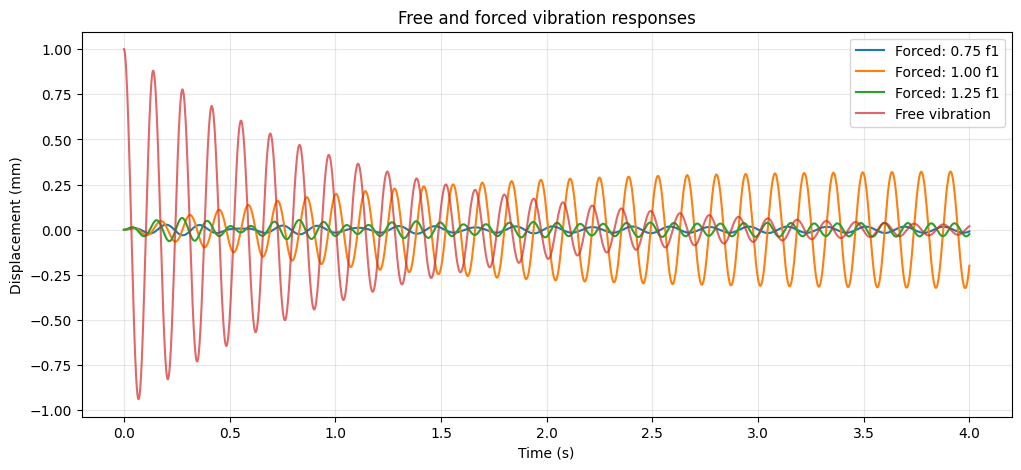

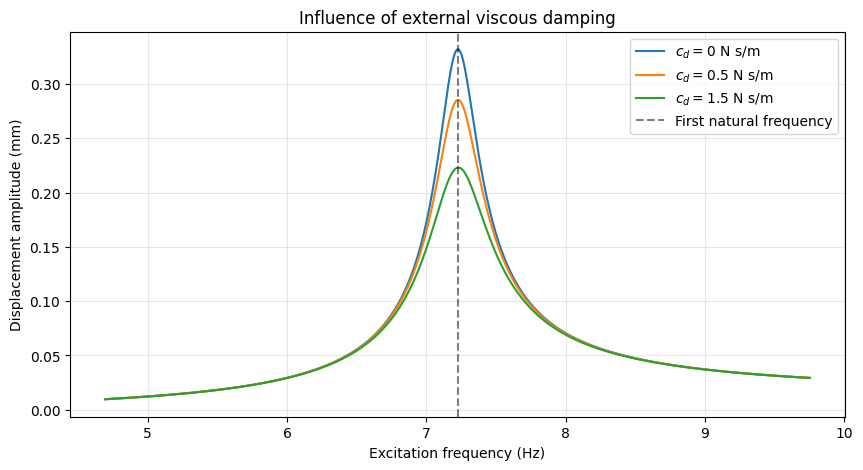

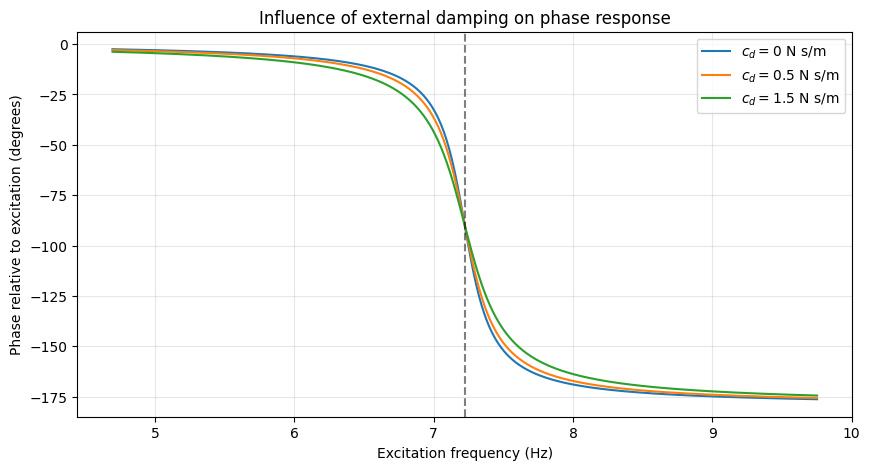

In [7]:
# First-mode properties from the modal decomposition
w1 = w[0]
f1 = w1 / (2 * np.pi)

p1 = p[0]  # Excitation factor
g1 = g[0]  # Dashpot attachment factor
h1 = h[0]  # Measurement factor

# Assumed inherent first-mode damping ratio
zeta_guess = 0.02


def H1(f, zeta1, cd=0):
    """
    Complex steady-state displacement response at the
    measurement location using the first-mode approximation.

    f     : excitation frequency (Hz)
    zeta1 : inherent first-mode damping ratio
    cd    : physical dashpot damping coefficient (N s/m)
    """
    om = 2 * np.pi * np.asarray(f)

    D1 = 2 * zeta1 * w1 + 2 * cd * g1**2 / mb

    return (
        (2 * u * om**2 / mb) * h1 * p1
        / (w1**2 - om**2 + 1j * om * D1)
    )


def first_mode_rhs(t, state, om, zeta1, cd=0, forced=True):
    """
    State-space representation of the normalized
    first-mode mathematical model.
    """
    q1, dq1 = state

    D1 = 2 * zeta1 * w1 + 2 * cd * g1**2 / mb

    force = (
        (2 * u * om**2 / mb) * p1 * np.cos(om * t)
        if forced else 0.0
    )

    ddq1 = force - D1 * dq1 - w1**2 * q1

    return [dq1, ddq1]


# --------------------------------------------------
# Free and forced vibration responses
# --------------------------------------------------

t = np.linspace(0, 4, 1601)

plt.figure(figsize=(12, 5))

for r in [0.75, 1.0, 1.25]:

    om = r * w1

    sol = solve_ivp(
        first_mode_rhs,
        [t[0], t[-1]],
        [0, 0],
        args=(om, zeta_guess, 0, True),
        t_eval=t,
        rtol=1e-7,
        atol=1e-9
    )

    plt.plot(
        t,
        1000 * h1 * sol.y[0],
        label=f'Forced: {r:.2f} f1'
    )


# Free vibration response
# Initial displacement of 1 mm at the measurement location

sol = solve_ivp(
    first_mode_rhs,
    [t[0], t[-1]],
    [0.001 / h1, 0],
    args=(0, zeta_guess, 0, False),
    t_eval=t,
    rtol=1e-7,
    atol=1e-9
)

plt.plot(
    t,
    1000 * h1 * sol.y[0],
    label='Free vibration',
    alpha=0.7
)

plt.xlabel('Time (s)')
plt.ylabel('Displacement (mm)')
plt.title('Free and forced vibration responses')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Steady-state amplitude response
# --------------------------------------------------

fgrid = np.linspace(0.65 * f1, 1.35 * f1, 501)

plt.figure(figsize=(10, 5))

for cd0 in [0, 0.5, 1.5]:

    plt.plot(
        fgrid,
        1000 * np.abs(H1(fgrid, zeta_guess, cd0)),
        label=f'$c_d={cd0:g}$ N s/m'
    )

plt.axvline(f1, color='black', ls='--', alpha=0.5,
            label='First natural frequency')

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Displacement amplitude (mm)')
plt.title('Influence of external viscous damping')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Steady-state phase response
# --------------------------------------------------

plt.figure(figsize=(10, 5))

for cd0 in [0, 0.5, 1.5]:

    phase = np.angle(
        H1(fgrid, zeta_guess, cd0),
        deg=True
    )

    plt.plot(
        fgrid,
        phase,
        label=f'$c_d={cd0:g}$ N s/m'
    )

plt.axvline(f1, color='black', ls='--', alpha=0.5)

plt.xlabel('Excitation frequency (Hz)')
plt.ylabel('Phase relative to excitation (degrees)')
plt.title('Influence of external damping on phase response')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Week 2 — Activity 3: dummy experimental recordings
The next cell acts as a virtual instrument. It uses a nine-function beam model, small measurement noise and run-to-run variation. Higher-mode damping is assumed only inside the synthetic generator; it is not estimated from the data. The unknown ground-truth coefficients must not be used in the estimator. CSV schemas are illustrative, not claimed VDAS export formats.

Free-decay columns: `setting` (-1 means dashpot removed; 0–1 are hypothetical installed settings), `run`, `time_s`, `displacement_m`. Forced-response columns additionally contain frequency, encoder angle and acceleration. The data are generated independently of the first-mode fitting procedure.

In [8]:
# Synthetic instrument only.
# No ground-truth damping values are passed to the estimator.

from scipy.linalg import expm

# Use the full modal model for the synthetic instrument
N = len(w)

# Modal properties
Lambda = np.diag(w**2)

# Ground-truth inherent modal damping ratios
truth_zeta = np.r_[0.013, np.full(N-1, 0.018)]

Ds = np.diag(2 * truth_zeta * w)


def true_cd(s):
    """
    Ground-truth dashpot calibration function.

    s < 0 represents the absence of the external dashpot.
    Returns the physical damping coefficient in N s/m.
    """
    return 0.0 if s < 0 else 0.18 + 1.8 * s**1.4


# Dashpot settings
settings = [-1., 0., 0.25, 0.5, 0.75, 1.]

records = []

# Sampling times
tfree = np.arange(0, 5, 0.005)
dt = tfree[1] - tfree[0]

for s in settings:

    for run, amp in enumerate([0.0007, 0.0012, 0.0007, 0.0012]):

        # Introduce small run-to-run variations in dashpot damping
        cd = true_cd(s) * (1 + rng.normal(0, 0.012))

        # Normalized modal damping matrix
        D = Ds + (2 * cd / mb) * np.outer(g, g)

        # Initial modal displacements
        q0 = np.zeros(N)

        # First-mode displacement contribution at the sensor
        q0[0] = amp / h[0]

        # Introduce a small higher-mode contamination
        if N >= 3 and abs(h[2]) > 1e-8:
            q0[2] = 0.000003 / h[2]

        # State-space system matrix
        state_matrix = np.block([
            [np.zeros((N, N)), np.eye(N)],
            [-Lambda,          -D]
        ])

        # Uniform-step exact propagation
        P = expm(state_matrix * dt)

        # Initial state: modal displacements and velocities
        state = np.r_[q0, np.zeros(N)]

        # Simulate measured displacement
        y = np.empty(len(tfree))

        for j, ti in enumerate(tfree):

            y[j] = h @ state[:N]

            state = P @ state

        # Add measurement noise and a run-dependent sensor offset
        y += rng.normal(0, 1.8e-6, len(tfree))
        y += rng.normal(0, 2e-6)

        records.append(pd.DataFrame({
            'setting': s,
            'run': run,
            'time_s': tfree,
            'displacement_m': y
        }))


# Save the synthetic experimental measurements
free_decay = pd.concat(records, ignore_index=True)

free_decay.to_csv(DATA / 'free_decay.csv', index=False)

print('Created', DATA / 'free_decay.csv')

Created me421_dummy_data/free_decay.csv


,setting,run,time_s,displacement_m
0,-1.0,0,0.000,0.000705
1,-1.0,0,0.005,0.000678
2,-1.0,0,0.010,0.000633
3,-1.0,0,0.015,0.000541
4,-1.0,0,0.020,0.000436


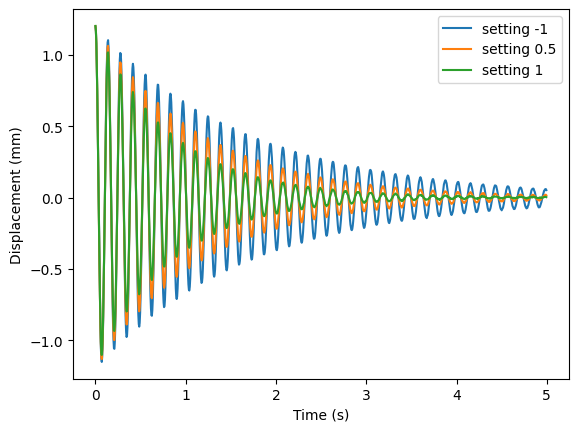

In [ ]:
# Import experimental data (replace path with actual exported data after column mapping).
free=pd.read_csv(DATA/'free_decay.csv')
display(free.head())
for s in [-1.,.5,1.]:
    g=free[(free.setting==s)&(free.run==1)]
    plt.plot(g.time_s,1000*g.displacement_m,label=f'setting {s:g}')
plt.xlabel('Time (s)'); plt.ylabel('Displacement (mm)'); plt.legend(); plt.show()

### Estimation of inherent damping and dashpot coefficient

In the absence of external excitation and the vibration absorber,
the first-mode approximation is governed by

$$
\ddot q_1+
2\zeta_{1,\mathrm{eff}}\omega_1\dot q_1
+\omega_1^2q_1=0,
$$

where

$$
\zeta_{1,\mathrm{eff}}
=
\zeta_1+\frac{c_dg_1^2}{m_b\omega_1}.
$$

For an underdamped system, the measured displacement can be
approximated by

$$
y(x_m,t)=
A e^{-\sigma t}\cos(\omega_dt+\phi)+y_0,
$$

where $y_0$ accounts for a possible sensor offset and

$$
\sigma=\zeta_{1,\mathrm{eff}}\omega_1,
\qquad
\omega_d=\sqrt{\omega_1^2-\sigma^2}.
$$

Fit the decaying sinusoid to each experimental run using nonlinear
least squares to estimate $\sigma$ and $\omega_d$.

The corresponding estimates of the natural frequency and effective
damping ratio are

$$
\widehat\omega_1=
\sqrt{\widehat\omega_d^2+\widehat\sigma^2},
\qquad
\widehat\zeta_{1,\mathrm{eff}}
=
\frac{\widehat\sigma}{\widehat\omega_1}.
$$

From the normalized first-mode equation, we have

$$
\sigma=
\zeta_1\omega_1+\frac{c_dg_1^2}{m_b}.
$$

Let $\overline\sigma_{\mathrm{removed}}$ denote the mean estimated
decay rate obtained with the external dashpot removed, and let
$\overline\sigma_s$ denote the mean estimated decay rate at
dashpot setting $s$.

The inherent first-mode damping ratio can then be estimated as

$$
\boxed{
\widehat\zeta_1=
\frac{\overline\sigma_{\mathrm{removed}}}{\omega_1}.
}
$$

The physical damping coefficient of the external dashpot at
setting $s$ can be estimated as

$$
\boxed{
\widehat c_d(s)=
\frac{m_b}{g_1^2}
\left(
\overline\sigma_s-
\overline\sigma_{\mathrm{removed}}
\right).
}
$$

Here, $\omega_1$ and $g_1=\chi_1(x_d)$ are obtained from the
modal decomposition of the mass-loaded beam.

The estimation of the physical dashpot coefficient requires
independently known values of $m_b$ and $g_1$, with $g_1\neq 0$.
The decay measurements alone identify the normalized damping
contributions, rather than the absolute physical damping coefficient.

A negative estimate of $c_d$ beyond experimental uncertainty would
indicate a modelling or measurement problem, rather than a physically
negative dashpot coefficient.

Note that the installed dashpot at setting zero need not correspond
to zero damping.

The sample standard deviation across repeated runs provides an
indicator of experimental repeatability, rather than a complete
uncertainty budget.

Since an off-centre dashpot introduces coupling between the natural
modes of the beam, the accuracy of these estimates depends on the
adequacy of the first-mode approximation.

Estimated inherent damping ratio: 0.01300
Standard error: 0.00000
Estimated normalized inherent damping: 1.18009 1/s


,sigma,sd,zeta,wn,rmse,n_runs,sigma_se,cd,cd_se
setting,,,,,,,,,
-1.00,0.590047,0.000403,0.013000,45.387187,0.000002,4,0.000202,0.000000,0.000000
0.00,0.643549,0.000787,0.014179,45.387016,0.000002,4,0.000393,0.180603,0.001492
0.25,0.719228,0.001819,0.015847,45.387130,0.000002,4,0.000910,0.436069,0.003145
0.50,0.847530,0.003238,0.018673,45.387438,0.000002,4,0.001619,0.869172,0.005508
0.75,0.998919,0.005208,0.022009,45.387745,0.000002,4,0.002604,1.380211,0.008816
1.00,1.181340,0.005129,0.026028,45.387762,0.000002,4,0.002565,1.996001,0.008684


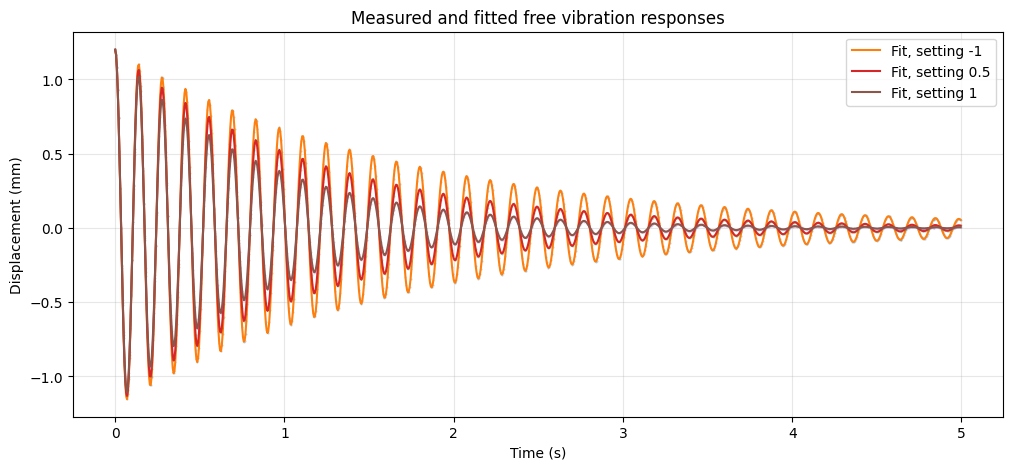

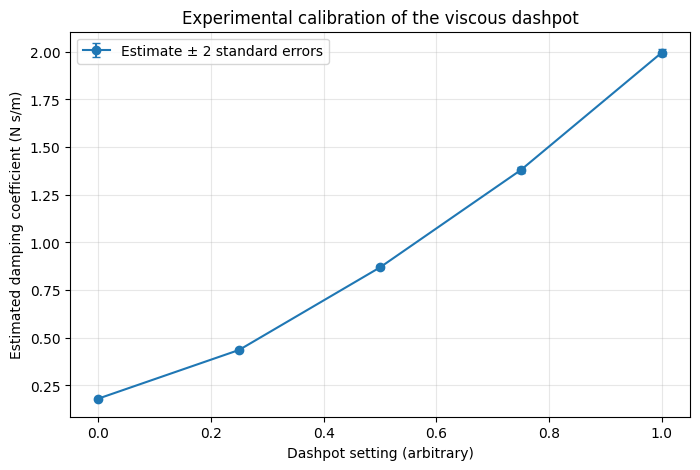

run,Small amplitude,Large amplitude,Difference
setting,,,
-1.00,0.013001,0.013000,-0.000001
0.00,0.014188,0.014170,-0.000018
0.25,0.015851,0.015842,-0.000008
0.50,0.018649,0.018697,0.000048
0.75,0.021956,0.022062,0.000106
1.00,0.026125,0.025930,-0.000195


In [9]:
# Read the synthetic experimental measurements
free = pd.read_csv(DATA / 'free_decay.csv')


def decay(t, B, D, sigma, wd, offset):
    """
    Underdamped free vibration response with a sensor offset.
    """
    return (
        np.exp(-sigma * t)
        * (B * np.cos(wd * t) + D * np.sin(wd * t))
        + offset
    )


def fit_decay(data):
    """
    Estimate the decay rate, damped natural frequency,
    natural frequency and effective damping ratio.
    """
    t = data.time_s.to_numpy()
    y = data.displacement_m.to_numpy()

    # Initial parameter estimates
    offset0 = np.mean(y[-100:])

    p0 = [
        y[0] - offset0,
        0.,
        zeta_guess * w1,
        w1,
        offset0
    ]

    res = least_squares(
        lambda p: (decay(t, *p) - y) / 1e-6,
        p0,
        bounds=(
            [-np.inf, -np.inf, 0, 0.8*w1, -np.inf],
            [ np.inf,  np.inf, 10, 1.2*w1, np.inf]
        ),
        x_scale='jac'
    )

    B, D, sigma, wd, offset = res.x

    # Estimated undamped natural frequency
    wn = np.hypot(sigma, wd)

    # Estimated effective damping ratio
    zeta = sigma / wn

    rmse = np.sqrt(
        np.mean((decay(t, *res.x) - y)**2)
    )

    return dict(
        sigma=sigma,
        wd=wd,
        wn=wn,
        zeta=zeta,
        rmse=rmse,
        success=res.success
    ), res.x


# --------------------------------------------------
# Estimate parameters for each experimental run
# --------------------------------------------------

fits = []

for (s, r), data in free.groupby(['setting', 'run']):

    est, _ = fit_decay(data)

    fits.append(dict(
        setting=s,
        run=r,
        **est
    ))

fit = pd.DataFrame(fits)

if not fit.success.all():
    raise RuntimeError('One or more decay fits did not converge.')


# --------------------------------------------------
# Summarize the estimated parameters at each setting
# --------------------------------------------------

summary = fit.groupby('setting').agg(
    sigma=('sigma', 'mean'),
    sd=('sigma', 'std'),
    zeta=('zeta', 'mean'),
    wn=('wn', 'mean'),
    rmse=('rmse', 'mean'),
    n_runs=('sigma', 'count')
)

# Standard error of the mean decay rate
summary['sigma_se'] = (
    summary.sd / np.sqrt(summary.n_runs)
)


# --------------------------------------------------
# Estimate inherent damping and dashpot coefficients
# --------------------------------------------------

if abs(g1) < 1e-8:
    raise ValueError('Dashpot coupling to the first mode is negligible.')

# Reference decay rate with the dashpot removed
sigma_removed = summary.loc[-1., 'sigma']

sigma_removed_se = summary.loc[-1., 'sigma_se']

# Estimated inherent first-mode damping ratio
zeta1_est = sigma_removed / w1

zeta1_se = sigma_removed_se / w1

# Estimated physical dashpot damping coefficients
summary['cd'] = (
    mb / g1**2
    * (summary.sigma - sigma_removed)
)

# Estimated standard errors of the dashpot coefficients
summary['cd_se'] = (
    mb / g1**2
    * np.sqrt(
        summary.sigma_se**2
        + sigma_removed_se**2
    )
)

# The removed-dashpot condition is the reference
summary.loc[-1., 'cd'] = 0.
summary.loc[-1., 'cd_se'] = 0.

print(f'Estimated inherent damping ratio: {zeta1_est:.5f}')
print(f'Standard error: {zeta1_se:.5f}')

print(
    f'Estimated normalized inherent damping: '
    f'{2*zeta1_est*w1:.5f} 1/s'
)

display(summary.round(6))


# --------------------------------------------------
# Compare measured and fitted free vibration responses
# --------------------------------------------------

plt.figure(figsize=(12, 5))

for s in [-1., 0.5, 1.]:

    data = free[
        (free.setting == s) & (free.run == 1)
    ]

    _, pfit = fit_decay(data)

    plt.plot(
        data.time_s,
        1000 * data.displacement_m,
        '.',
        ms=1,
        alpha=0.3
    )

    plt.plot(
        data.time_s,
        1000 * decay(data.time_s, *pfit),
        label=f'Fit, setting {s:g}'
    )

plt.xlabel('Time (s)')
plt.ylabel('Displacement (mm)')
plt.title('Measured and fitted free vibration responses')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# Dashpot calibration curve
# --------------------------------------------------

cal = summary.loc[summary.index >= 0].copy()

plt.figure(figsize=(8, 5))

plt.errorbar(
    cal.index,
    cal.cd,
    yerr=2 * cal.cd_se,
    fmt='o-',
    capsize=3,
    label='Estimate ± 2 standard errors'
)

plt.xlabel('Dashpot setting (arbitrary)')
plt.ylabel('Estimated damping coefficient (N s/m)')
plt.title('Experimental calibration of the viscous dashpot')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


def cd_est(s):
    """
    Estimate the physical dashpot damping coefficient
    by piecewise-linear interpolation.
    """
    if s == -1:
        return 0.

    if not cal.index.min() <= s <= cal.index.max():
        raise ValueError('Setting outside calibrated range')

    return float(np.interp(s, cal.index, cal.cd))


# --------------------------------------------------
# Investigate the influence of initial amplitude
# --------------------------------------------------

amplitude_comparison = (
    fit.groupby(['setting', fit.run % 2])
    .zeta.mean()
    .unstack()
    .rename(columns={
        0: 'Small amplitude',
        1: 'Large amplitude'
    })
)

amplitude_comparison['Difference'] = (
    amplitude_comparison['Large amplitude']
    - amplitude_comparison['Small amplitude']
)

display(amplitude_comparison.round(6))

## Activity 4 — Independent forced-response validation

Conduct a new frequency sweep for the beam with the external
dashpot removed and with the dashpot installed at setting $s=0.5$.

Use the inherent damping ratio $\widehat\zeta_1$ and the calibrated
dashpot coefficient $\widehat c_d(s)$ obtained from the free-decay
experiments to predict the steady-state response.

According to the first-mode approximation, the complex amplitude
of the modal coordinate is

$$
\boxed{
\widehat q_1(\omega)=
\frac{2u\omega^2p_1/m_b}
{\omega_1^2-\omega^2+
i\omega\left(
2\widehat\zeta_1\omega_1+
\frac{2\widehat c_d(s)g_1^2}{m_b}
\right)}.
}
$$

The corresponding complex displacement amplitude at the
measurement location is

$$
\widehat y(x_m,\omega)=h_1\widehat q_1(\omega),
$$

while the complex acceleration amplitude at the exciter is

$$
\widehat{\ddot y}(x_f,\omega)
=-\omega^2p_1\widehat q_1(\omega).
$$

At each excitation frequency, estimate the harmonic coefficients
of the measured displacement by linear least-squares regression
against the measured encoder angle $\theta$:

$$
y=B\cos\theta+D\sin\theta+y_0.
$$

Using the complex representation

$$
y=\operatorname{Re}
\left(\widehat y e^{i\theta}\right)+y_0,
$$

the estimated complex displacement amplitude is

$$
\boxed{
\widehat y=B-iD.
}
$$

The corresponding displacement amplitude and phase relative
to the encoder reference are

$$
|\widehat y|=\sqrt{B^2+D^2},
\qquad
\phi=\arg(\widehat y).
$$

Apply the same regression procedure to the measured acceleration.

Since the displacement sensor and accelerometer are co-located
in the synthetic experiment ($x_m=x_f$), their complex amplitudes
should satisfy

$$
\boxed{
\widehat{\ddot y}=-\omega^2\widehat y.
}
$$

Compare the experimentally estimated displacement and acceleration
amplitudes and phases with the predictions of the calibrated
first-mode mathematical model.

Do not re-estimate the damping parameters using these measurements,
since the objective is to independently validate the mathematical
model and the parameters identified from the free-decay experiments.

The synthetic instrument uses all nine retained natural modes of
the mass-loaded beam, governed by

$$
\ddot q+
\left(
D_s+\frac{2c_d}{m_b}gg^T
\right)\dot q+
\Lambda q
=
\frac{2u\omega^2}{m_b}p\cos(\omega t).
$$

Consequently, discrepancies between the measured and predicted
responses may arise from measurement noise, experimental variability
and the limitations of the first-mode approximation.

Assess whether retaining additional natural modes improves the
predicted response.

The synthetic instrument also supports the vibration absorber
experiments in Week 4 through the extended modal formulation
developed previously.

,config,setting,frequency_Hz,H,Hacc
0,bare,-1.0,5.417696,0.000017-0.000001j,-0.019152+0.001267j
1,bare,-1.0,5.477893,0.000018-0.000001j,-0.020905+0.001747j
2,bare,-1.0,5.538089,0.000019-0.000001j,-0.023119+0.001288j
3,bare,-1.0,5.598286,0.000020-0.000001j,-0.024201+0.001550j
4,bare,-1.0,5.658483,0.000021-0.000001j,-0.027075+0.001972j


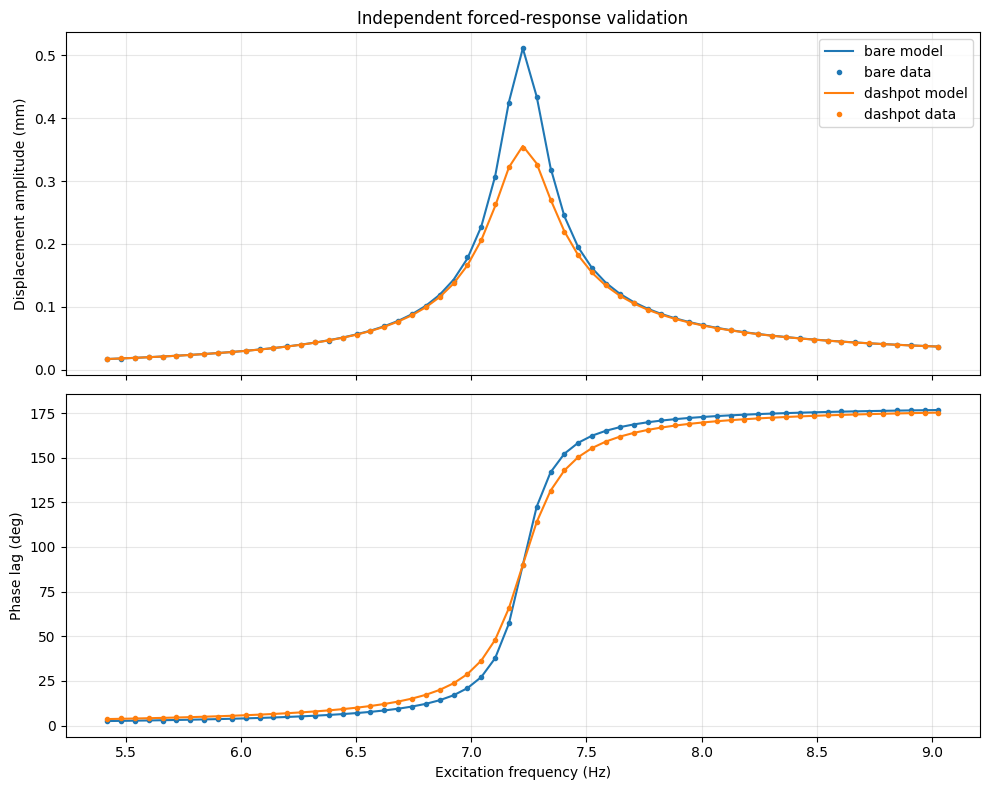

,configuration,complex_RMSE_mm,measured_peak_Hz,predicted_peak_Hz,measured_peak_mm,predicted_peak_mm,acceleration_consistency_RMSE_m_s2
0,bare,0.00076,7.22359,7.22468,0.51161,0.51101,0.00333
1,dashpot,0.00074,7.22359,7.22612,0.35291,0.35579,0.00237


In [10]:
def virtual_H(f, s, absorber=None):
    """
    Synthetic instrument using the full normalized modal model.

    f        : excitation frequency (Hz)
    s        : dashpot setting
    absorber : None or (ma, fa, xa)

        ma : absorber mass (kg)
        fa : absorber natural frequency (Hz)
        xa : absorber attachment location (m)

    Returns the complex displacement amplitudes at the
    displacement sensor and exciter locations.
    """

    om = 2 * np.pi * f

    # Full normalized modal damping matrix
    D = Ds + (2 * true_cd(s) / mb) * np.outer(g, g)

    # Normalized stiffness operator
    Omega = np.diag(w**2)

    # Normalized excitation amplitude
    force = (2 * u * om**2 / mb) * p

    if absorber is not None:

        ma, fa, xa = absorber

        wa = 2 * np.pi * fa
        ka = ma * wa**2

        # Modal attachment factors of the absorber
        ar = V.T @ basis(xa, N)

        # Undamped vibration absorber
        ca = 0.
        zeta_a = 0.

        # Extended normalized damping matrix
        D = np.block([
            [
                D + (2 * ca / mb) * np.outer(ar, ar),
                -(2 * ca / mb) * ar[:, None]
            ],
            [
                -2 * zeta_a * wa * ar[None, :],
                np.array([[2 * zeta_a * wa]])
            ]
        ])

        # Extended normalized stiffness operator
        Omega = np.block([
            [
                Omega + (2 * ka / mb) * np.outer(ar, ar),
                -(2 * ka / mb) * ar[:, None]
            ],
            [
                -wa**2 * ar[None, :],
                np.array([[wa**2]])
            ]
        ])

        # Extended excitation amplitude
        force = np.r_[force, 0.]

    # Complex steady-state response
    Qhat = np.linalg.solve(
        Omega - om**2 * np.eye(len(force)) + 1j * om * D,
        force
    )

    # Extract the beam modal coordinates
    qhat = Qhat[:N]

    # Complex displacement at sensor and exciter
    H = h @ qhat
    Hf = p @ qhat

    return H, Hf


# --------------------------------------------------
# Generate synthetic frequency sweep measurements
# --------------------------------------------------

def write_sweep(path, configs, freqs):

    rows = []

    for name, s, absr in configs:

        for f in freqs:

            H, Hf = virtual_H(f, s, absr)

            # Independent sensor gain variations
            H *= 1 + rng.normal(0, 0.006)
            Hf *= 1 + rng.normal(0, 0.006)

            # Sampling times and encoder angle
            tt = np.arange(0, 1.5, 0.0025)

            om = 2 * np.pi * f

            theta = om * tt + 0.23

            e = np.exp(1j * theta)

            # Synthetic displacement measurement
            displacement = (
                np.real(H * e)
                + rng.normal(0, 2e-6, len(tt))
            )

            # Synthetic acceleration measurement
            acceleration = (
                np.real(-om**2 * Hf * e)
                + rng.normal(0, 0.008, len(tt))
            )

            rows.append(pd.DataFrame({
                'config': name,
                'setting': s,
                'frequency_Hz': f,
                'time_s': tt,
                'encoder_rad': theta,
                'displacement_m': displacement,
                'acceleration_m_s2': acceleration
            }))

    pd.concat(rows, ignore_index=True).to_csv(
        path, index=False
    )

    return path


# Independent forced-response validation experiment
write_sweep(
    DATA / 'validation_sweep.csv',
    [
        ('bare', -1., None),
        ('dashpot', 0.5, None)
    ],
    np.linspace(0.75*f1, 1.25*f1, 61)
)


# --------------------------------------------------
# Extract complex amplitudes by harmonic regression
# --------------------------------------------------

def extract_sweep(path):

    raw = pd.read_csv(path)

    rows = []

    for (name, s, f), data in raw.groupby(
        ['config', 'setting', 'frequency_Hz']
    ):

        theta = data.encoder_rad.to_numpy()

        # Harmonic regression matrix
        X = np.column_stack([
            np.cos(theta),
            np.sin(theta),
            np.ones(len(theta))
        ])

        # Displacement regression
        B, D, _ = np.linalg.lstsq(
            X,
            data.displacement_m,
            rcond=None
        )[0]

        # Acceleration regression
        Ba, Da, _ = np.linalg.lstsq(
            X,
            data.acceleration_m_s2,
            rcond=None
        )[0]

        rows.append(dict(
            config=name,
            setting=s,
            frequency_Hz=f,
            H=B - 1j*D,
            Hacc=Ba - 1j*Da
        ))

    return pd.DataFrame(rows)


val = extract_sweep(DATA / 'validation_sweep.csv')

display(val.head())


# --------------------------------------------------
# Independent validation of the identified model
# --------------------------------------------------

fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

validation_results = []

for name, data in val.groupby('config'):

    f = data.frequency_Hz.to_numpy()

    obs = data.H.to_numpy()

    s = data.setting.iloc[0]

    # Predictions using experimentally identified parameters
    pred = H1(
        f,
        zeta1_est,
        cd_est(s)
    )

    # Displacement amplitude
    line, = axs[0].plot(
        f,
        1000 * np.abs(pred),
        label=name + ' model'
    )

    color = line.get_color()

    axs[0].plot(
        f,
        1000 * np.abs(obs),
        '.',
        color=color,
        label=name + ' data'
    )

    # Phase lag
    axs[1].plot(
        f,
        -np.angle(pred, deg=True),
        color=color
    )

    axs[1].plot(
        f,
        -np.angle(obs, deg=True),
        '.',
        color=color
    )

    # Complex displacement prediction error
    rmse = np.sqrt(
        np.mean(np.abs(pred - obs)**2)
    )

    # Predicted peak using a finer frequency grid
    dense = np.linspace(f.min(), f.max(), 10001)

    pp = np.abs(
        H1(dense, zeta1_est, cd_est(s))
    )

    # Acceleration consistency for co-located sensors
    acc_error = np.sqrt(
        np.mean(
            np.abs(
                data.Hacc.to_numpy()
                + (2*np.pi*f)**2 * obs
            )**2
        )
    )

    validation_results.append({
        'configuration': name,
        'complex_RMSE_mm': 1000 * rmse,
        'measured_peak_Hz': f[np.argmax(np.abs(obs))],
        'predicted_peak_Hz': dense[np.argmax(pp)],
        'measured_peak_mm': 1000 * np.max(np.abs(obs)),
        'predicted_peak_mm': 1000 * np.max(pp),
        'acceleration_consistency_RMSE_m_s2': acc_error
    })


axs[0].set_ylabel('Displacement amplitude (mm)')
axs[0].set_title('Independent forced-response validation')
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].set_ylabel('Phase lag (deg)')
axs[1].set_xlabel('Excitation frequency (Hz)')
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(pd.DataFrame(validation_results).round(5))

For the SDOF rotating-unbalance response the peak occurs at $\omega_n/\sqrt{1-2\zeta^2}$ when $\zeta<1/\sqrt2$; this differs from the fixed-force resonance formula. The independently measured sweep may miss the exact peak because of finite frequency spacing. Compare model residuals with measurement noise and check whether increasing the model order would materially improve prediction. The first-mode approximation is justified only over the tested band, not for all frequencies.

### Part I conclusion (end of Week 2)
The free-decay results identify the inherent first-mode damping and an effective calibration of the dashpot. Repeatability and amplitude checks are available above. The independent sweep tests both amplitude and phase. The baseline for Part II is the system with the dashpot at setting 0.5; the bare system is also retained for comparison. Full modal damping, real equipment tension and mounting constraints have not been experimentally established by this synthetic example.

# Part II — vibration absorber design and implementation (end of Week 4)
## Week 3 — Activity 5: extend the model
Let $r(t)$ denote the absolute displacement of the absorber mass $m_a$. Attach an ideal undamped spring $k_a$ at $x_a$, with $g_i=\phi_i(x_a)$. The force on the beam is $k_a(r-g^Tq)$, and the absorber obeys $m_a\ddot r+k_a(r-g^Tq)=0$. The extended matrices are
$$\widetilde M=\begin{bmatrix}M&0\\0&m_a\end{bmatrix},\quad\widetilde C=\begin{bmatrix}C_s+c_dbb^T&0\\0&0\end{bmatrix},\quad\widetilde K=\begin{bmatrix}K+k_agg^T&-k_ag\\-k_ag^T&k_a\end{bmatrix}.$$
The excitation is $[a^T,0]^Tu\omega^2\cos\omega t$. For the first-mode approximation, replace $M,K,C_s,b,g,a$ by $M_1,K_1,C_{s1},b_1,\psi(x_a),1$. In the frequency domain,
$$\widehat Q=(\widetilde K-\omega^2\widetilde M+i\omega\widetilde C)^{-1}\begin{bmatrix}u\omega^2\\0\end{bmatrix}.$$
The sensor amplitude is $|h_1\widehat Q_1|$, and the absorber relative stroke amplitude is $|\widehat Q_2-\psi(x_a)\widehat Q_1|$. At $\omega=\sqrt{k_a/m_a}$ the ideal absorber equation requires zero displacement at its attachment; for the single-mode model with nonzero coupling, this implies zero beam response. In a multi-mode beam, other locations need not have zero displacement. The absorber introduces two nearby resonances; reducing vibration at one frequency alone is not sufficient for a variable-speed machine.

Selected ma=0.240 kg, fa=7.238 Hz, ka=496.38 N/m
Robust peak reduction vs fixed dashpot baseline: 97.0%
Worst tested stroke: 1.361 mm
Undamped coupled frequencies (Hz): [5.92876604 8.81881352]


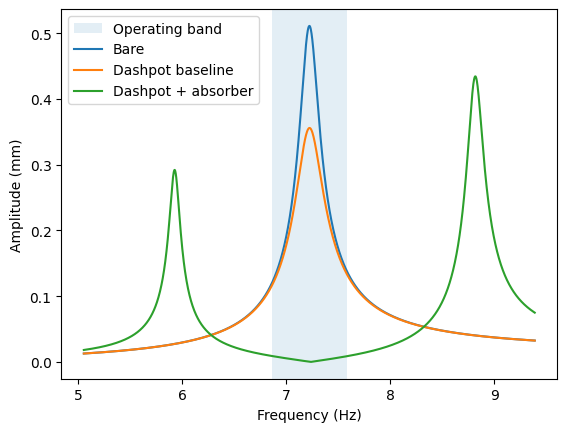

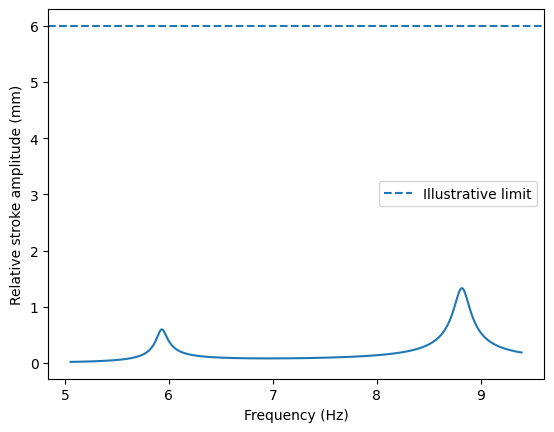

In [ ]:
def absorber_H(f,ma,fa,xa,s):
    f=np.asarray(f); om=2*np.pi*f; ka=ma*(2*np.pi*fa)**2; g=basis(xa,9)@v
    MM=np.diag([M1,ma]); CC=np.diag([Cs+cd_est(s)*b1*b1,0.]); KK=np.array([[K1+ka*g*g,-ka*g],[-ka*g,ka]])
    mat=KK-om[...,None,None]**2*MM+1j*om[...,None,None]*CC
    F=np.stack([u*om**2,np.zeros_like(om)],axis=-1)
    Q=np.linalg.solve(mat,F[...,None])[...,0]
    return h1*Q[...,0], Q[...,1]-g*Q[...,0], np.sqrt(eigh(KK,MM,eigvals_only=True))/(2*np.pi)
# Hypothetical design envelope, NOT equipment limits.
# Keep dashpot setting fixed so improvement is attributable to absorber.
s_base=.5; xa=L/2
band=np.linspace(.95*f1,1.05*f1,601); check=np.linspace(.70*f1,1.30*f1,1801)
base_peak=max(abs(H1(band,Cs,cd_est(s_base))))
# Assume three candidate moving masses and a continuous tuning interval.
# Actual adjustable mass/stiffness range must be confirmed.
rows=[]
for ma in [.12,.18,.24]:
    for fa in np.linspace(.94*f1,1.06*f1,121):
        H,stroke,_=absorber_H(band,ma,fa,xa,s_base)
        # Robust objective over ±1% tuning uncertainty, and both band and wider sweep for stroke.
        worst=0.; maxstroke=0.
        for err in [-.01,0,.01]:
            Hr,Sr,_=absorber_H(band,ma,fa*(1+err),xa,s_base)
            _,Sc,_=absorber_H(check,ma,fa*(1+err),xa,s_base)
            worst=max(worst,max(abs(Hr))); maxstroke=max(maxstroke,max(abs(Sc)))
        rows.append(dict(ma=ma,fa=fa,ka=ma*(2*np.pi*fa)**2,worst_m=worst,stroke_m=maxstroke))
designs=pd.DataFrame(rows); stroke_limit=.006 # illustrative 6 mm amplitude constraint
feasible=designs[designs.stroke_m<=stroke_limit]
if feasible.empty: raise RuntimeError('No feasible candidate: revise the illustrative design envelope')
best=feasible.sort_values(['worst_m','ma']).iloc[0]; ma,fa,ka=best[['ma','fa','ka']]
print(f'Selected ma={ma:.3f} kg, fa={fa:.3f} Hz, ka={ka:.2f} N/m')
print(f'Robust peak reduction vs fixed dashpot baseline: {100*(1-best.worst_m/base_peak):.1f}%')
print(f'Worst tested stroke: {1000*best.stroke_m:.3f} mm')
H,S,modes=absorber_H(check,ma,fa,xa,s_base); print('Undamped coupled frequencies (Hz):',modes)
plt.axvspan(band.min(),band.max(),alpha=.12,label='Operating band')
plt.plot(check,1000*abs(H1(check,Cs)),label='Bare')
plt.plot(check,1000*abs(H1(check,Cs,cd_est(s_base))),label='Dashpot baseline')
plt.plot(check,1000*abs(H),label='Dashpot + absorber'); plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(); plt.show()
plt.plot(check,1000*abs(S)); plt.axhline(1000*stroke_limit,ls='--',label='Illustrative limit'); plt.xlabel('Frequency (Hz)'); plt.ylabel('Relative stroke amplitude (mm)'); plt.legend(); plt.show()

### Design justification and implementation plan
The operating range is chosen as ±5% of the original first natural frequency to represent modest speed variation. The criterion is the maximum sensor displacement amplitude across this band, including three tested tuning errors of −1%, 0 and +1%. This is a sampled robustness check, not a rigorous bound for all errors. The chosen dashpot setting is unchanged from the baseline. Candidate absorber masses, mounting position and stroke limit are hypothetical; on the real apparatus select from measured feasible configurations. The wider sweep reveals the additional resonances and stroke demand; any actual experiment must remain within staff-approved amplitude, speed and stroke limits. A dense numerical sweep is not permission to run through unsafe resonances.

Before Week 4, measure the absorber's effective moving mass and verify its tuning independently if possible. Account for any fixed bracket mass in the beam model. Secure all components, establish a safe start/stop sequence and select frequency increments small enough to resolve peaks. Record the same sensor signal and encoder phase at each speed after transients decay. If the absorber and dashpot cannot be mounted together, repeat design calculations for the physically permitted configuration.

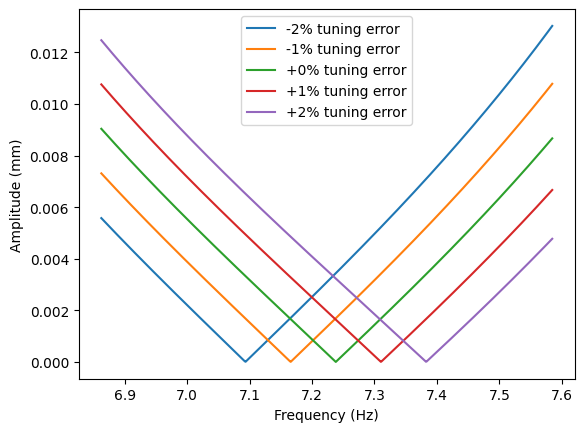

Dashpot -1: predicted in-band peak 0.0090 mm
Dashpot 0: predicted in-band peak 0.0090 mm
Dashpot 0.5: predicted in-band peak 0.0090 mm
Dashpot 1: predicted in-band peak 0.0090 mm


In [ ]:
# Sensitivity plots and a comparison with single-frequency tuning.
for err in [-.02,-.01,0,.01,.02]:
    HH,_,_=absorber_H(band,ma,fa*(1+err),xa,s_base)
    plt.plot(band,1000*abs(HH),label=f'{100*err:+.0f}% tuning error')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(); plt.show()
for s in [-1,0,.5,1]:
    HH,_,_=absorber_H(band,ma,fa,xa,s)
    print(f'Dashpot {s:g}: predicted in-band peak {1000*max(abs(HH)):.4f} mm')

## Week 4 — Activity 6: synthetic implementation and independent verification
The virtual instrument now generates fresh recordings for the bare beam, fixed dashpot baseline, and selected absorber combined with the dashpot. A 0.5% tuning offset represents a small implementation error. It is not used to refit the model before comparison. This is a simulated implementation, not evidence that a real device has been installed or tested.

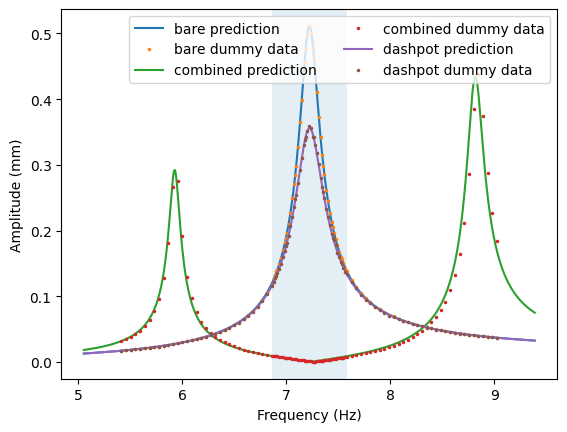

,measured_peak_mm,predicted_peak_mm,complex_rmse_mm
config,,,
bare,0.51143,0.51097,0.00102
combined,0.00973,0.00904,0.02353
dashpot,0.35901,0.35573,0.00099


Illustrative measured reduction relative to dashpot baseline: 97.3%


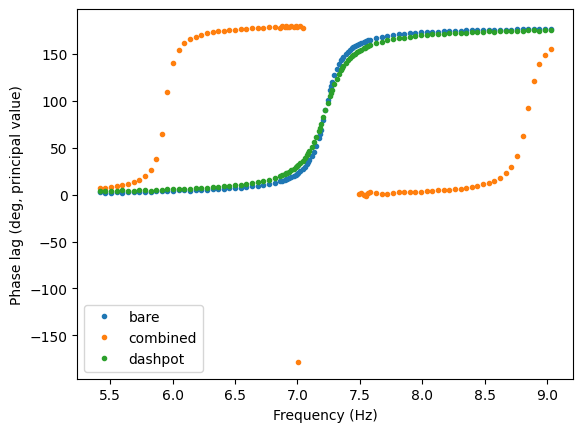

In [ ]:
verify_freq=np.unique(np.r_[np.linspace(.75*f1,1.25*f1,81),np.linspace(band.min(),band.max(),41)])
write_sweep(DATA/'absorber_verification.csv',[
    ('bare',-1,None),('dashpot',s_base,None),('combined',s_base,(ma,fa*1.005,xa))],verify_freq)
ver=extract_sweep(DATA/'absorber_verification.csv')
plt.axvspan(band.min(),band.max(),alpha=.12)
for name,g in ver.groupby('config'):
    f=g.frequency_Hz.to_numpy(); obs=g.H.to_numpy()
    pred=absorber_H(check,ma,fa,xa,s_base)[0] if name=='combined' else H1(check,Cs,cd_est(g.setting.iloc[0]))
    plt.plot(check,1000*abs(pred),label=name+' prediction'); plt.plot(f,1000*abs(obs),'.',ms=3,label=name+' dummy data')
plt.xlabel('Frequency (Hz)'); plt.ylabel('Amplitude (mm)'); plt.legend(ncol=2); plt.show()
rows=[]
for name,g in ver.groupby('config'):
    f=g.frequency_Hz.to_numpy(); obs=g.H.to_numpy(); mask=(f>=band.min()-1e-9)&(f<=band.max()+1e-9)
    pred=absorber_H(f,ma,fa,xa,s_base)[0] if name=='combined' else H1(f,Cs,cd_est(g.setting.iloc[0]))
    rows.append(dict(config=name,measured_peak_mm=1000*max(abs(obs[mask])),predicted_peak_mm=1000*max(abs(pred[mask])),complex_rmse_mm=1000*np.sqrt(np.mean(abs(pred-obs)**2))))
results=pd.DataFrame(rows).set_index('config'); display(results.round(5))
reduction=100*(1-results.loc['combined','measured_peak_mm']/results.loc['dashpot','measured_peak_mm'])
print(f'Illustrative measured reduction relative to dashpot baseline: {reduction:.1f}%')
# Phase is ill-conditioned at antiresonance; omit points below 5 micrometres.
for name,g in ver.groupby('config'):
    ok=abs(g.H)>5e-6; plt.plot(g.frequency_Hz[ok],-np.angle(g.H[ok],deg=True),'.',label=name)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Phase lag (deg, principal value)'); plt.legend(); plt.show()

### Conclusions and critical evaluation (end of Week 4)
The numerical and synthetic experimental results above demonstrate how to move from a distributed beam model to a calibrated first-mode approximation and then to an absorber design. The comparison against the fixed-dashpot baseline isolates the effect of the absorber. The design targets a limited speed range; the two additional peaks outside or near that range and the relative absorber stroke must be examined before installation. Tuning error, neglected higher modes, non-viscous losses, attachment mass and uncertain tension can all affect real performance. A discrepancy between prediction and measurement is a reason to investigate and revise the model, not to discard the measurement.

For actual submission, replace synthetic data with measured recordings, provide the verified equipment constraints, repeat the uncertainty assessment, report the actual achieved reduction and document any necessary design changes. This example identifies only the first-mode inherent damping, not a complete physical structural damping law. The assumed dashpot calibration and absorber feasibility must be independently established on the actual equipment.

In [ ]:
# Export data and useful estimated results for reproducibility.
import shutil
summary.to_csv(DATA/'estimated_damping.csv'); results.to_csv(DATA/'verification_summary.csv')
archive=shutil.make_archive('ME421_dummy_data','zip',DATA)
print('Data archive:',archive)
# In Colab, uncomment to download:
# from google.colab import files
# files.download(archive)

Data archive: /mnt/data/ME421_dummy_data.zip
